# Classificação da condição periodontal a partir do microbioma oral — versão conjunta (v3)

**Pergunta:** a composição do microbioma oral permite distinguir participantes com e sem periodontite? Quanto as características do participante (idade, sexo, renda, saúde geral) acrescentam a essa informação, e quanto o microbioma acrescenta a elas?

Esta versão junta os dois caminhos desenvolvidos a partir da base comum de 11/nov:

- **Da v2 (Renato):** preparo dos dados e das covariáveis do NHANES, filtro de gêneros por prevalência e abundância (Zhuang et al.), anotação taxonômica, PCA exploratória, estratificação pelas quatro categorias de gravidade, Modelos A (só táxons) e B (táxons + covariáveis), métricas clínicas (sensibilidade, especificidade, acurácia balanceada, PR-AUC, Brier), calibração e importância por permutação.
- **Da versão do Diego:** avaliação em **10 divisões treino/teste** (média ± desvio), linha de base sem informação (`DummyClassifier`), filtros e ajustes calculados **só no treino** de cada divisão, comparação dos classificadores das aulas, seleção sequencial (SFS) e ajuste de hiperparâmetros por validação cruzada aninhada.

A base metodológica são os notebooks da disciplina; quando uma técnica não aparece nas aulas, isso é indicado no texto.

| Modelo | Atributos | Para quê |
|---|---|---|
| **A** | só gêneros do microbioma | responde à pergunta principal |
| **B** | gêneros + covariáveis | modelo mais completo, usado na demonstração |
| **C** | só covariáveis | mede quanto o microbioma acrescenta ao que já se sabe do participante |

## 0. Preparação do ambiente

**Rode esta célula antes de qualquer outra.** Ela funciona tanto no Google Colab quanto no computador:

- **No Colab:** baixa o código do projeto do repositório e instala as bibliotecas nas versões exatas usadas no trabalho. Na primeira vez, a sessão **reinicia sozinha** depois da instalação (aparece um aviso de que a sessão travou, é esperado): quando reconectar, rode esta mesma célula de novo.
- **No computador:** não instala nada (o ambiente já foi criado com `uv sync`, veja o README).

Nos dois casos, ela baixa os dados do NHANES direto do site do CDC para a pasta `datasets/`. Os arquivos que já estiverem lá e íntegros não são baixados de novo.

In [1]:
import os
import sys

# Endereço do repositório do projeto (usado só no Colab).
URL_REPOSITORIO = "https://github.com/dpontejs/periodontite-microbioma-ml.git"

if "google.colab" in sys.modules:
    # 1) Baixa o código do projeto (só na primeira vez).
    if not os.path.exists("baixar_dados.py"):
        if not os.path.exists("periodontite-microbioma-ml"):
            if not URL_REPOSITORIO:
                raise RuntimeError("Preencha URL_REPOSITORIO no início desta célula.")
            !git clone -q {URL_REPOSITORIO} periodontite-microbioma-ml
        %cd periodontite-microbioma-ml

    # 2) Instala as bibliotecas nas versões do projeto e reinicia a sessão
    #    (só na primeira vez; na segunda execução esta parte é pulada).
    if not os.path.exists(".ambiente_instalado"):
        !command -v uv > /dev/null || pip install -q uv
        !uv pip install -q --system -r requirements.txt
        open(".ambiente_instalado", "w").close()
        print("Bibliotecas instaladas. A sessão vai reiniciar agora.")
        print("Quando o Colab reconectar, rode ESTA MESMA CÉLULA de novo.")
        os.kill(os.getpid(), 9)

# 3) Baixa os dados do NHANES para a pasta datasets/.
from baixar_dados import baixar

baixar()

ok       ALQ_F.xpt
ok       ALQ_G.xpt
ok       BPQ_F.xpt
ok       BPQ_G.xpt
ok       DEMO_F.xpt
ok       DEMO_G.xpt
ok       DIQ_F.xpt
ok       DIQ_G.xpt
ok       MCQ_F.xpt
ok       MCQ_G.xpt
ok       OHXPER_F.xpt


ok       OHXPER_G.xpt
ok       PAQ_F.xpt
ok       PAQ_G.xpt
ok       dada2rsv-genus-count.txt
ok       dada2rsv-genus-relative.txt
ok       dada2rsv-taxonomy-annotate.txt
Pronto: 17 arquivos em /home/diegoponte/mlbioinfo/periodontite-microbioma-ml/datasets


[]

In [2]:
# Importação de todas as bibliotecas

# Bibliotecas padrão do Python
from itertools import combinations
from pathlib import Path
import re
import warnings

# Manipulação e visualização de dados
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

# Estatística e distâncias
from scipy import stats
from scipy.stats import mannwhitneyu, kruskal, rankdata, norm
from scipy.spatial.distance import pdist, squareform

# Pré-processamento, redução de dimensionalidade e validação
from sklearn.preprocessing import (
    Normalizer,
    StandardScaler,
    LabelEncoder,
    OneHotEncoder,
    label_binarize
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest

# Algoritmos de classificação
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier

# Métricas e avaliação dos modelos
from sklearn.metrics import (
    make_scorer,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score,
    brier_score_loss,
    roc_curve,
    precision_recall_curve
)
from sklearn.calibration import calibration_curve

# XGBoost é necessário para a comparação dos seis algoritmos.
try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError(
        "O pacote xgboost não está instalado. Execute `%pip install xgboost` "
        "e reinicie o kernel."
    ) from exc

# adjustText é opcional: a PCA possui alternativa quando a biblioteca não está instalada.
try:
    from adjustText import adjust_text
except ImportError:
    adjust_text = None


## 1. Obtenção e carregamento inicial dos dados

O *National Health and Nutrition Examination Survey* (NHANES) é um programa norte-americano que reúne informações de entrevistas, exames físicos e análises laboratoriais. Neste projeto, são utilizadas as tabelas de microbioma oral e os exames periodontais dos ciclos de 2009–2010 e 2011–2012.

As amostras de enxágue bucal foram processadas por sequenciamento do gene 16S rRNA, região V4. Em linhas gerais, o fluxo laboratorial e bioinformático incluiu extração de DNA, amplificação por PCR, sequenciamento, processamento das sequências com DADA2 e atribuição taxonômica com o banco SILVA. O resultado é uma matriz de contagens microbianas por participante, acompanhada de tabelas de abundância relativa e anotação taxonômica.

A imagem resume esse fluxo experimental e computacional.

![fluxograma_rna_seq](images/fluxograma_rna_seq.jpeg)


### 1.1 Conceitos necessários para compreender os dados

**Gene 16S rRNA.** É um marcador molecular utilizado para caracterizar comunidades bacterianas e arqueanas. As regiões conservadas permitem a amplificação por primers, enquanto as regiões variáveis fornecem informação para diferenciar grupos taxonômicos. O sequenciamento de uma região do gene permite descrever parte da composição microbiana, mas não representa necessariamente a resolução de espécie para todos os táxons.

**DADA2 e ASVs.** O DADA2 modela erros de sequenciamento e infere *Amplicon Sequence Variants* (ASVs), isto é, sequências distintas após a correção dos erros. As ASVs são posteriormente associadas a classificações taxonômicas por comparação com um banco de referência, neste conjunto, SILVA.

**Tabela RSV.** A tabela utilizada no projeto não contém a sequência SV1032, descrita na documentação de origem como um táxon não bacteriano associado a padrões anômalos nas análises de diversidade beta.

**Diversidade alfa e beta.** A diversidade alfa resume características da comunidade dentro de cada participante, por exemplo, riqueza e distribuição das abundâncias. A diversidade beta compara a composição entre participantes e é representada por uma matriz de distâncias entre amostras.

A primeira tabela carregada contém as contagens brutas dos táxons para os ciclos de 2009–2012. A normalização e a integração com os dados periodontais são realizadas nas etapas seguintes.


In [3]:
# Localiza os arquivos tanto na pasta "datasets" quanto no diretório de trabalho
# ou em /mnt/data, conforme a estrutura do ambiente de execução.
_candidatos_dados = [Path("datasets"), Path("."), Path("/mnt/data")]
DATA_DIR = next(
    (p for p in _candidatos_dados if (p / "dada2rsv-genus-count.txt").exists()),
    Path("datasets")
)
print("Diretório de dados utilizado:", DATA_DIR.resolve())

df_microbiome = pd.read_csv(
    DATA_DIR / "dada2rsv-genus-count.txt",
    sep="\t"
)
df_microbiome.columns = df_microbiome.columns.str.strip()

print("Dimensões:", df_microbiome.shape)
display(df_microbiome.head())
print("\nTipos de dados:")
print(df_microbiome.dtypes.value_counts())


Diretório de dados utilizado: /home/diegoponte/mlbioinfo/periodontite-microbioma-ml/datasets


Dimensões: (9848, 1350)


,SEQN,RSV_genus1,RSV_genus2,RSV_genus3,RSV_genus4,RSV_genus5,RSV_genus6,RSV_genus7,RSV_genus8,RSV_genus9,...,RSV_genus1340,RSV_genus1341,RSV_genus1342,RSV_genus1343,RSV_genus1344,RSV_genus1345,RSV_genus1346,RSV_genus1347,RSV_genus1348,RSV_genus1349
0,57816.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,59605.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,56372.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,55484.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,55685.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,24,0,0,0,0,0



Tipos de dados:
int64      1349
float64       1
Name: count, dtype: int64


In [4]:
df_microbiome.describe()

,SEQN,RSV_genus1,RSV_genus2,RSV_genus3,RSV_genus4,RSV_genus5,RSV_genus6,RSV_genus7,RSV_genus8,RSV_genus9,...,RSV_genus1340,RSV_genus1341,RSV_genus1342,RSV_genus1343,RSV_genus1344,RSV_genus1345,RSV_genus1346,RSV_genus1347,RSV_genus1348,RSV_genus1349
count,9847.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,...,9848.000000,9848.0,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.0,9848.000000
mean,61919.993297,0.001219,0.136271,0.000305,0.005788,0.001320,0.005077,0.006093,0.003452,0.066714,...,0.052396,0.0,0.024878,0.006702,6.458367,0.014115,0.248477,0.057778,0.0,0.077579
std,5866.344665,0.102762,13.372855,0.030231,0.400146,0.095061,0.503844,0.575174,0.235880,5.854635,...,5.199669,0.0,2.282276,0.665074,127.110438,0.930893,8.340846,2.989745,0.0,7.658529
min,51624.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
25%,56828.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
50%,62076.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
75%,66994.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
max,71916.000000,10.000000,1327.000000,3.000000,38.000000,8.000000,50.000000,57.000000,20.000000,579.000000,...,516.000000,0.0,226.000000,66.000000,8922.000000,69.000000,449.000000,233.000000,0.0,760.000000


## 2. Exploração, controle de qualidade e anotação taxonômica da matriz de contagens

Antes da integração com os exames periodontais, a tabela microbiana passa por verificações estruturais: validade de `SEQN`, conversão das contagens para formato numérico, identificação de valores ausentes/negativos, duplicatas e amostras sem contagens utilizáveis.

Após remover amostras cuja soma de contagens é zero, será aplicada uma filtragem taxonômica inspirada no estudo de Zhuang et al. (2026): serão removidos os táxons que atendam **simultaneamente** aos dois critérios: (1) abundância relativa média inferior a **0,02%** e (2) detecção em menos de **20%** das amostras. Para operacionalizar o primeiro critério, a média será calculada sobre as abundâncias relativas provisórias de cada táxon em todos os participantes com contagens utilizáveis. A prevalência será a proporção de participantes com contagem maior que zero.

Embora os critérios sejam calculados por meio de uma matriz relativa provisória, a filtragem será aplicada à matriz de contagens; a normalização L1 definitiva ocorrerá somente depois. A matriz de contagens sem filtragem será preservada para uma análise de sensibilidade. Se algum participante ficar sem nenhum táxon retido, será removido das duas matrizes e os critérios serão recalculados até que todos os perfis mantidos tenham ao menos um atributo microbiano. A filtragem não utiliza os rótulos periodontais.

**Atenção metodológica:** como a elegibilidade dos táxons é estimada na matriz completa antes da divisão treino/teste, essa etapa é uma triagem não supervisionada que utiliza a distribuição de todos os participantes. A análise de sensibilidade com a matriz não filtrada permitirá verificar a dependência dos resultados em relação a esse critério; a validação externa continua sendo necessária para uma estimativa independente de generalização.


In [5]:
if "SEQN" not in df_microbiome.columns:
    raise ValueError(
        "A coluna SEQN não foi encontrada. "
        "Confira os nomes exibidos na célula anterior."
    )

# Transformar ID de float64 em Int64
df_microbiome["SEQN"] = pd.to_numeric(
    df_microbiome["SEQN"],
    errors="coerce" # transforma em NaN no caso de valores ausentes
).astype("Int64")

# Contabilizar IDs ausentes/inválidos antes da limpeza.
ids_invalidos = int(df_microbiome["SEQN"].isna().sum())
print("SEQN ausentes ou inválidos antes da limpeza:", ids_invalidos)

# Remover registros sem identificador, pois não podem ser integrados por SEQN.
df_microbiome = df_microbiome.dropna(subset=["SEQN"]).copy()

print("\nRegistros removidos por SEQN ausente/inválido:", ids_invalidos)
print("SEQN ausentes após a limpeza:", df_microbiome["SEQN"].isna().sum())
print("SEQN duplicados:", df_microbiome["SEQN"].duplicated().sum())

# Separa as colunas microbianas do identificador
microbial_cols = [
    col for col in df_microbiome.columns
    if col != "SEQN"
]

# criamos uma nova matriz contendo exclusivamente as contagens microbianas
X_counts = df_microbiome[microbial_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

print("\nNúmero de variáveis microbianas:", len(microbial_cols))
print("Valores ausentes na matriz:", X_counts.isna().sum().sum()) # 1sum coluna, 2sum total de células
print("Valores negativos:", (X_counts < 0).sum().sum())

display(X_counts)


SEQN ausentes ou inválidos antes da limpeza: 1

Registros removidos por SEQN ausente/inválido: 1
SEQN ausentes após a limpeza: 0
SEQN duplicados: 0

Número de variáveis microbianas: 1349


Valores ausentes na matriz: 0
Valores negativos: 0


,RSV_genus1,RSV_genus2,RSV_genus3,RSV_genus4,RSV_genus5,RSV_genus6,RSV_genus7,RSV_genus8,RSV_genus9,RSV_genus10,...,RSV_genus1340,RSV_genus1341,RSV_genus1342,RSV_genus1343,RSV_genus1344,RSV_genus1345,RSV_genus1346,RSV_genus1347,RSV_genus1348,RSV_genus1349
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,24,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9843,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9844,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9845,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9846,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### 2.1 Filtragem taxonômica por abundância relativa e prevalência

Com a matriz de contagens estruturada e validada na célula anterior, esta etapa aplicará a triagem taxonômica antes da normalização definitiva. Primeiro, serão removidas amostras sem qualquer contagem utilizável. Em seguida, a matriz original será preservada (`X_counts_sem_filtro`) para permitir uma análise de sensibilidade.

Para cada táxon, será calculada uma abundância relativa provisória por participante e, a partir dela, a média entre participantes. Também será calculada a prevalência de detecção, isto é, a proporção de participantes com contagem maior que zero. Um táxon será excluído somente quando **ambos** os critérios forem atendidos: abundância relativa média <0,02% e prevalência <20%.

A filtragem será aplicada às contagens, não à matriz relativa provisória. Se algum participante ficar sem nenhum táxon após a filtragem, ele será retirado tanto da matriz filtrada quanto da matriz sem filtragem, mantendo os mesmos participantes nas duas representações. Os critérios serão então recalculados até que todos os participantes restantes tenham ao menos um táxon retido. A normalização L1 definitiva será realizada posteriormente, na seção 4.

> **Nota da versão conjunta.** Os números desta seção descrevem o filtro aplicado a **todos** os participantes, para caracterizar os dados. Nos modelos (seções 6 em diante), o mesmo critério é **recalculado apenas com os dados de treino** de cada divisão, como um passo do pipeline (`FiltroPrevalencia`, no arquivo `microbioma.py`). Assim, os participantes do teste não influenciam quais gêneros são mantidos.

In [6]:
# --------------------------------------------------
# 1. Verificar a soma das contagens em cada participante
# --------------------------------------------------
row_totals = X_counts.sum(axis=1)
print("Participantes com soma zero antes da filtragem:", int(row_totals.eq(0).sum()))

# Exclui amostras sem nenhuma contagem utilizável.
valid_rows = row_totals > 0
df_microbiome = df_microbiome.loc[valid_rows].reset_index(drop=True)
X_counts = X_counts.loc[valid_rows].reset_index(drop=True)

if X_counts.isna().any().any():
    raise ValueError("A matriz de contagens contém valores ausentes após a conversão numérica.")
if (X_counts < 0).any().any():
    raise ValueError("A matriz de contagens contém valores negativos.")

# --------------------------------------------------
# 2. Preservar a matriz completa para análise de sensibilidade
# --------------------------------------------------
X_counts_sem_filtro = X_counts.copy()
microbial_cols_sem_filtro = X_counts.columns.tolist()

# --------------------------------------------------
# 3. Filtragem iterativa por abundância relativa e prevalência
# --------------------------------------------------
LIMIAR_ABUNDANCIA_RELATIVA = 0.0002  # 0,02% como proporção
LIMIAR_PREVALENCIA = 0.20            # 20% dos participantes

# A triagem é recalculada caso algum participante fique sem táxons retidos.
# Isso mantém a prevalência/abundância estimadas na amostra que será analisada.
linhas_ativas = pd.Series(True, index=X_counts_sem_filtro.index)
seqn_sem_taxon_retido = []
iteracao_filtro = 0

while True:
    iteracao_filtro += 1
    if iteracao_filtro > 20:
        raise RuntimeError("A filtragem não convergiu após 20 iterações.")

    contagens_ativas = X_counts_sem_filtro.loc[linhas_ativas]
    totais_ativos = contagens_ativas.sum(axis=1)
    abundancia_relativa_provisoria = contagens_ativas.div(
        totais_ativos,
        axis=0
    )

    abundancia_media_taxon = abundancia_relativa_provisoria.mean(axis=0)
    prevalencia_taxon = (contagens_ativas > 0).mean(axis=0)

    mascara_remover = (
        (abundancia_media_taxon < LIMIAR_ABUNDANCIA_RELATIVA)
        & (prevalencia_taxon < LIMIAR_PREVALENCIA)
    )
    microbial_cols_removidos = mascara_remover.index[mascara_remover].tolist()
    microbial_cols = mascara_remover.index[~mascara_remover].tolist()

    if not microbial_cols:
        raise ValueError("A filtragem removeu todos os táxons. Revise os limiares.")

    matriz_candidata_filtrada = contagens_ativas.loc[:, microbial_cols]
    linhas_sem_taxon = matriz_candidata_filtrada.sum(axis=1).eq(0)

    print(
        f"Iteração {iteracao_filtro}: {len(microbial_cols)} táxons mantidos; "
        f"{int(linhas_sem_taxon.sum())} participante(s) sem táxon retido."
    )

    if not linhas_sem_taxon.any():
        break

    indices_remover = linhas_sem_taxon.index[linhas_sem_taxon]
    seqn_sem_taxon_retido.extend(
        df_microbiome.loc[indices_remover, "SEQN"].astype("Int64").tolist()
    )
    linhas_ativas.loc[indices_remover] = False

# Atualizar ambas as matrizes para o mesmo conjunto de participantes.
# A matriz sem filtro mantém todos os atributos originais.
X_counts_sem_filtro = X_counts_sem_filtro.loc[linhas_ativas].reset_index(drop=True)
df_microbiome = df_microbiome.loc[linhas_ativas].reset_index(drop=True)
X_counts = X_counts_sem_filtro.loc[:, microbial_cols].copy()

# Resumo final dos critérios, calculados sobre a amostra analítica retida.
resumo_filtro_taxons = pd.DataFrame({
    "Código": X_counts_sem_filtro.columns,
    "Abundância relativa média (%)": abundancia_media_taxon.reindex(
        X_counts_sem_filtro.columns
    ).to_numpy() * 100,
    "Prevalência de detecção (%)": prevalencia_taxon.reindex(
        X_counts_sem_filtro.columns
    ).to_numpy() * 100
})
resumo_filtro_taxons["Removido"] = resumo_filtro_taxons["Código"].isin(
    microbial_cols_removidos
)

# --------------------------------------------------
# 4. Resumir o efeito da filtragem
# --------------------------------------------------
print("\nCritérios aplicados simultaneamente:")
print(f"Abundância relativa média < {LIMIAR_ABUNDANCIA_RELATIVA * 100:.02f}%")
print(f"Prevalência de detecção < {LIMIAR_PREVALENCIA * 100:.0f}%")
print("Os dois critérios precisam ser atendidos para remover um táxon.")

print("\nNúmero de táxons antes da filtragem:", len(microbial_cols_sem_filtro))
print("Táxons removidos:", len(microbial_cols_removidos))
print("Táxons mantidos:", len(microbial_cols))
print("Proporção removida:", f"{len(microbial_cols_removidos) / len(microbial_cols_sem_filtro):.1%}")
print("Participantes removidos por ficarem sem táxon retido:", len(seqn_sem_taxon_retido))
if seqn_sem_taxon_retido:
    print("SEQN removido(s):", seqn_sem_taxon_retido)

print("\nResumo dos táxons removidos (15 primeiras linhas):")
display(
    resumo_filtro_taxons.loc[resumo_filtro_taxons["Removido"]]
    .sort_values(
        ["Prevalência de detecção (%)", "Abundância relativa média (%)"]
    )
    .head(15)
    .round(5)
)

print("\nDimensões da matriz filtrada:", X_counts.shape)
print("Dimensões da matriz sem filtro (mesmos participantes):", X_counts_sem_filtro.shape)
print("Participantes com soma zero após a filtragem:", int(X_counts.sum(axis=1).eq(0).sum()))
X_counts.info()

Participantes com soma zero antes da filtragem: 17
Iteração 1: 107 táxons mantidos; 1 participante(s) sem táxon retido.


Iteração 2: 107 táxons mantidos; 0 participante(s) sem táxon retido.

Critérios aplicados simultaneamente:
Abundância relativa média < 0.02%
Prevalência de detecção < 20%
Os dois critérios precisam ser atendidos para remover um táxon.

Número de táxons antes da filtragem: 1349
Táxons removidos: 1242
Táxons mantidos: 107
Proporção removida: 92.1%
Participantes removidos por ficarem sem táxon retido: 1
SEQN removido(s): [54732]

Resumo dos táxons removidos (15 primeiras linhas):


,Código,Abundância relativa média (%),Prevalência de detecção (%),Removido
24,RSV_genus25,0.0,0.0,True
25,RSV_genus26,0.0,0.0,True
77,RSV_genus78,0.0,0.0,True
103,RSV_genus104,0.0,0.0,True
106,RSV_genus107,0.0,0.0,True
111,RSV_genus112,0.0,0.0,True
121,RSV_genus122,0.0,0.0,True
139,RSV_genus140,0.0,0.0,True
140,RSV_genus141,0.0,0.0,True
201,RSV_genus202,0.0,0.0,True



Dimensões da matriz filtrada: (9829, 107)
Dimensões da matriz sem filtro (mesmos participantes): (9829, 1349)
Participantes com soma zero após a filtragem: 0
<class 'pandas.DataFrame'>
RangeIndex: 9829 entries, 0 to 9828
Columns: 107 entries, RSV_genus35 to RSV_genus1322
dtypes: int64(107)
memory usage: 8.0 MB


### 2.2 Anotação taxonômica: associação entre os códigos RSV e a classificação SILVA v123

Após a filtragem, os atributos mantidos ainda são identificados na matriz por códigos como `RSV_genus1`, `RSV_genus2` e assim por diante. Nesta etapa, esses códigos são associados às classificações disponíveis no arquivo de anotação do NHANES, baseado na versão SILVA v123.

A função `rotular_taxons()` recupera o nível taxonômico mais específico que estiver disponível entre domínio, filo, classe, ordem, família e gênero. Portanto, nem todo código será necessariamente apresentado como gênero. Quando houver classificações repetidas ou ausência de anotação, o código RSV será mantido no rótulo para evitar ambiguidades.

Os nomes taxonômicos são utilizados nas tabelas e figuras destinadas à interpretação. Os nomes originais das colunas (`RSV_genus...`) são preservados nas matrizes e nos modelos, garantindo rastreabilidade e compatibilidade com as etapas computacionais seguintes. A tabela abaixo documenta uma única vez a correspondência dos táxons efetivamente mantidos após a filtragem.


In [7]:
# --------------------------------------------------
# 1. Carregar o arquivo de anotação taxonômica do NHANES
# --------------------------------------------------

taxonomia = pd.read_csv(
    DATA_DIR / "dada2rsv-taxonomy-annotate.txt",
    sep="\t",
    dtype=str,
    encoding="utf-8-sig"
)
taxonomia.columns = taxonomia.columns.str.strip()

colunas_taxonomia_necessarias = {"Name", "Taxonomy in SILVA v123"}
colunas_ausentes = colunas_taxonomia_necessarias - set(taxonomia.columns)

if colunas_ausentes:
    raise ValueError(
        "O arquivo de anotação taxonômica não contém as colunas esperadas: "
        f"{sorted(colunas_ausentes)}"
    )

# O arquivo identifica os códigos de gênero pelo prefixo RSV_genus.
taxonomia_generos = taxonomia[
    taxonomia["Name"].astype("string").str.startswith("RSV_genus", na=False)
].copy()

taxonomia_generos["Name"] = taxonomia_generos["Name"].str.strip()
taxonomia_generos["Taxonomy in SILVA v123"] = (
    taxonomia_generos["Taxonomy in SILVA v123"].str.strip()
)

# Em caso de códigos duplicados no arquivo de referência, manter a primeira
# ocorrência e informar a quantidade para fins de rastreabilidade.
n_codigos_duplicados_taxonomia = int(
    taxonomia_generos["Name"].duplicated(keep="first").sum()
)
taxonomia_generos = taxonomia_generos.drop_duplicates(
    subset="Name",
    keep="first"
)

mapa_taxonomia = dict(
    zip(
        taxonomia_generos["Name"],
        taxonomia_generos["Taxonomy in SILVA v123"]
    )
)

# --------------------------------------------------
# 2. Converter a classificação SILVA em rótulos legíveis
# --------------------------------------------------

NOMES_NIVEIS_TAXONOMICOS = [
    "domínio", "filo", "classe", "ordem", "família", "gênero"
]
TERMOS_DESCONHECIDOS = {
    "", "NA", "NAN", "N/A", "UNKNOWN", "UNCLASSIFIED", "UNCULTURED"
}


def rotular_taxons(colunas):
    """
    Retorna o nível taxonômico mais específico disponível para cada código.
    Mantém o código RSV quando não há anotação ou quando os rótulos se repetem.
    """
    rotulos = []

    for codigo in colunas:
        classificacao = mapa_taxonomia.get(str(codigo))

        if not isinstance(classificacao, str) or not classificacao.strip():
            rotulos.append(str(codigo))
            continue

        niveis = [nivel.strip() for nivel in classificacao.split(";")]
        nivel_conhecido = None

        for posicao in range(
            min(len(niveis), len(NOMES_NIVEIS_TAXONOMICOS)) - 1,
            -1,
            -1
        ):
            if niveis[posicao].upper() not in TERMOS_DESCONHECIDOS:
                nivel_conhecido = posicao
                break

        if nivel_conhecido is None:
            rotulo = f"Táxon não classificado [{codigo}]"
        else:
            nome = re.sub(
                r"^(?:D_\d+__|[dkpcofgs]__)",
                "",
                niveis[nivel_conhecido],
                flags=re.IGNORECASE
            )
            nome = nome.replace("_", " ").strip()
            categoria = NOMES_NIVEIS_TAXONOMICOS[nivel_conhecido]
            rotulo = (
                nome
                if categoria == "gênero"
                else f"{nome} ({categoria})"
            )

        rotulos.append(rotulo)

    # Acrescentar o código RSV aos rótulos repetidos.
    contagem_rotulos = pd.Series(rotulos).value_counts()
    return [
        (
            f"{rotulo} [{codigo}]"
            if contagem_rotulos[rotulo] > 1
            or "não classificado" in rotulo.lower()
            else rotulo
        )
        for codigo, rotulo in zip(colunas, rotulos)
    ]


# --------------------------------------------------
# 3. Criar uma tabela única para os táxons retidos
# --------------------------------------------------

rotulos_taxons_retidos = rotular_taxons(microbial_cols)
mapa_rotulo_taxonomico = dict(zip(microbial_cols, rotulos_taxons_retidos))

tabela_anotacao_taxonomica = pd.DataFrame({
    "Código na matriz": microbial_cols,
    "Classificação original — SILVA v123": [
        mapa_taxonomia.get(codigo, "Não encontrado no arquivo de anotação")
        for codigo in microbial_cols
    ],
    "Rótulo utilizado nas tabelas e figuras": rotulos_taxons_retidos
})

n_codigos_com_anotacao = sum(
    codigo in mapa_taxonomia
    and isinstance(mapa_taxonomia[codigo], str)
    and bool(mapa_taxonomia[codigo].strip())
    for codigo in microbial_cols
)

print("Táxons retidos na matriz:", len(microbial_cols))
print("Códigos com anotação SILVA disponível:", n_codigos_com_anotacao)
print("Códigos sem anotação disponível:", len(microbial_cols) - n_codigos_com_anotacao)
print("Códigos duplicados no arquivo taxonômico (ocorrências excedentes):",
      n_codigos_duplicados_taxonomia)

display(tabela_anotacao_taxonomica)


Táxons retidos na matriz: 107
Códigos com anotação SILVA disponível: 107
Códigos sem anotação disponível: 0
Códigos duplicados no arquivo taxonômico (ocorrências excedentes): 0


,Código na matriz,Classificação original — SILVA v123,Rótulo utilizado nas tabelas e figuras
0,RSV_genus35,Bacteria;Actinobacteria;Actinobacteria;Actinom...,Actinomyces
1,RSV_genus39,Bacteria;Actinobacteria;Actinobacteria;Actinom...,Actinomycetaceae (família)
2,RSV_genus44,Bacteria;Actinobacteria;Actinobacteria;Bifidob...,Alloscardovia
3,RSV_genus45,Bacteria;Actinobacteria;Actinobacteria;Bifidob...,Bifidobacterium
4,RSV_genus49,Bacteria;Actinobacteria;Actinobacteria;Bifidob...,Parascardovia
...,...,...,...
102,RSV_genus1307,Bacteria;Spirochaetae;Spirochaetes;Spirochaeta...,Treponema 2
103,RSV_genus1309,Bacteria;Synergistetes;Synergistia;Synergistal...,Fretibacterium
104,RSV_genus1314,Bacteria;Tenericutes;Mollicutes;Acholeplasmata...,Acholeplasma
105,RSV_genus1320,Bacteria;Tenericutes;Mollicutes;Mollicutes_RF9...,Mollicutes RF9 (ordem)


## 3. Preparação dos dados periodontais e definição dos desfechos

Os exames periodontais dos ciclos NHANES 2009–2010 (`OHXPER_F`) e 2011–2012 (`OHXPER_G`) são carregados e examinados separadamente. Primeiro, são verificadas as estruturas e as variáveis disponíveis; em seguida, os ciclos são reunidos em uma única tabela, preservando uma coluna que identifica sua origem.

A classificação periodontal será construída somente para participantes com exame completo e sem exclusão médica do exame.


In [8]:
df_perio_f = pd.read_sas(
    DATA_DIR / "OHXPER_F.xpt",
    format="xport"
)

df_perio_g = pd.read_sas(
    DATA_DIR / "OHXPER_G.xpt",
    format="xport"
)

df_perio_f.columns = df_perio_f.columns.str.strip().str.upper()
df_perio_g.columns = df_perio_g.columns.str.strip().str.upper()

print("Dimensões do ciclo F:", df_perio_f.shape)
print("Dimensões do ciclo G:", df_perio_g.shape)

print("Colunas exclusivas do ciclo F:",
      sorted(set(df_perio_f.columns) - set(df_perio_g.columns)))

print("Colunas exclusivas do ciclo G:",
      sorted(set(df_perio_g.columns) - set(df_perio_f.columns)))


Dimensões do ciclo F: (5037, 508)
Dimensões do ciclo G: (4365, 508)
Colunas exclusivas do ciclo F: []
Colunas exclusivas do ciclo G: []


In [9]:
df_perio_f["NHANES_CYCLE"] = "2009-2010"
df_perio_g["NHANES_CYCLE"] = "2011-2012"

df_perio_total = pd.concat(
    [df_perio_f, df_perio_g],
    ignore_index=True
)

df_perio_total["SEQN"] = pd.to_numeric(
    df_perio_total["SEQN"],
    errors="coerce"
).astype("Int64")

print("Dimensões combinadas:", df_perio_total.shape)
print("IDs ausentes:", df_perio_total["SEQN"].isna().sum())
print("IDs duplicados:", df_perio_total["SEQN"].duplicated().sum())

display(
    df_perio_total[
        ["SEQN", "OHDPDSTS", "OHDEXCLU", "NHANES_CYCLE"]
    ].sample(5)
)


Dimensões combinadas: (9402, 509)
IDs ausentes: 0
IDs duplicados: 0


,SEQN,OHDPDSTS,OHDEXCLU,NHANES_CYCLE
3583,59105,1.0,2.0,2009-2010
6526,65522,1.0,2.0,2011-2012
5603,63396,1.0,2.0,2011-2012
1903,55732,1.0,2.0,2009-2010
6348,65129,1.0,2.0,2011-2012


As variáveis de controle determinam se o exame periodontal pode ser utilizado:

- `OHDPDSTS`: código 1 indica exame periodontal completo; 2, exame parcial; 3, exame não realizado.
- `OHDEXCLU`: código 1 indica exclusão médica do exame; código 2 indica ausência dessa exclusão.

Os códigos e suas descrições podem ser conferidos nos [codebooks oficiais do ciclo 2009–2010](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/OHXPER_F.htm) e do [ciclo 2011–2012](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2011/DataFiles/OHXPER_G.htm).


### 3.1 Seleção dos exames periodontais válidos

A classificação depende de medidas clínicas registradas nos exames periodontais. Por isso, são mantidos os participantes com exame completo (`OHDPDSTS == 1`) e sem exclusão médica (`OHDEXCLU == 2`). Essa restrição evita interpretar medidas ausentes por exame incompleto como evidência de ausência de periodontite.


In [10]:
df_perio_total["OHDPDSTS"] = pd.to_numeric(
    df_perio_total["OHDPDSTS"],
    errors="coerce"
)

df_perio_total["OHDEXCLU"] = pd.to_numeric(
    df_perio_total["OHDEXCLU"],
    errors="coerce"
)

df_perio_complete = df_perio_total.loc[
    (df_perio_total["OHDPDSTS"] == 1) & # o exame periodontal foi completo
    (df_perio_total["OHDEXCLU"] == 2)   # o participante não foi excluído do exame por razões médicas
].copy()

print("Participantes com exame periodontal completo:",
      df_perio_complete.shape[0])

display(df_perio_complete.round(1))


Participantes com exame periodontal completo: 7770


,SEQN,OHDEXSTS,OHDPDSTS,OHDEXCLU,OHX02CJD,OHX02CJM,OHX02CJS,OHX02CJP,OHX02CJL,OHX02CJA,...,OHX31PCP,OHX31PCL,OHX31PCA,OHX31LAD,OHX31LAM,OHX31LAS,OHX31LAP,OHX31LAL,OHX31LAA,NHANES_CYCLE
0,51624,1.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.0,1.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,2009-2010
1,51628,1.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,2009-2010
2,51630,1.0,1.0,2.0,1.0,0.0,1.0,1.0,0.0,1.0,...,2.0,2.0,4.0,1.0,2.0,3.0,1.0,2.0,3.0,2009-2010
3,51633,1.0,1.0,2.0,99.0,99.0,99.0,99.0,99.0,99.0,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,2009-2010
4,51635,1.0,1.0,2.0,99.0,99.0,99.0,99.0,99.0,99.0,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,2009-2010
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9397,71904,1.0,1.0,2.0,0.0,0.0,0.0,0.0,-2.0,0.0,...,1.0,1.0,2.0,1.0,1.0,2.0,1.0,1.0,2.0,2011-2012
9398,71907,1.0,1.0,2.0,-4.0,-4.0,-2.0,0.0,0.0,0.0,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,2011-2012
9399,71908,1.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2011-2012
9400,71912,1.0,1.0,2.0,99.0,-2.0,-1.0,-2.0,-4.0,-4.0,...,2.0,4.0,4.0,2.0,2.0,2.0,3.0,6.0,5.0,2011-2012


### 3.2 Critérios para a classificação periodontal

A classificação adotada é a definição epidemiológica CDC/AAP (*Centers for Disease Control and Prevention* / *American Academy of Periodontology*) para vigilância da periodontite. Ela utiliza perda de inserção clínica (*clinical attachment loss*, CAL) e profundidade de sondagem (*periodontal probing depth*, PPD) em sítios interproximais. O resultado distingue quatro categorias: sem periodontite, leve, moderada e grave.

Fonte metodológica: [artigo disponível no PubMed Central](https://pmc.ncbi.nlm.nih.gov/articles/PMC6005373/).

**Distinção importante:** a definição CDC/AAP é voltada à vigilância epidemiológica populacional e não equivale ao estadiamento clínico individual proposto pela classificação periodontal de 2017 ([AAP](https://www.perio.org/press-release/american-academy-of-periodontology-releases-proceedings-from-the-2017-world-workshop-on-the-classification-of-periodontal-and-peri-implant-diseases-and-conditions/)). A categoria “sem periodontite” indica que os critérios epidemiológicos não foram atingidos; não significa, por si só, ausência de qualquer condição gengival ou periodontal.

Para consulta complementar sobre o sistema clínico de 2017, está disponível o [resumo da classificação de estágio clínico periodontal e peri-implantar](https://www.ict.unesp.br/Home/ensino/pos-graduacao/biopatologiabucal/versionenespaol/resumo-do-novo-esquema-de-classificacao-para-doencas-e-condicoes-periodontais-e-peri-implantes--world-workshop-2017.pdf).

Nos arquivos NHANES, `OHXnnPC...` representa a profundidade de sondagem, `OHXnnLA...` representa a perda de inserção clínica calculada e `OHXnnCJ...` representa a distância entre a margem gengival e a junção cemento-esmalte. Para os critérios utilizados, são selecionadas as medidas `PC` e `LA`.

A definição de vigilância considera os quatro sítios interproximais por dente. Na nomenclatura adotada nos arquivos, são utilizados os sufixos D, S, P e A; os sítios médios vestibulares e linguais não entram nesses critérios. A figura identifica os sítios examinados.

![alt text](images/probing_sites.jpeg)

**Por que utilizar sítios interproximais?** A definição privilegia sítios interproximais para aumentar a especificidade da classificação populacional. A perda de inserção em sítios médios pode ocorrer por motivos não necessariamente relacionados à periodontite, como recessão associada à escovação traumática ou abrasão. A exclusão desses sítios reduz classificações falso-positivas e favorece a comparabilidade entre levantamentos epidemiológicos. Trata-se de uma escolha operacional para vigilância, não de uma afirmação de que os sítios médios sejam clinicamente irrelevantes.

#### Esquema quantitativo dos critérios CDC/AAP

A classificação é baseada em CAL e PPD nos sítios interproximais. Para os critérios que exigem dois dentes, devem ser contabilizados dentes distintos; basta que pelo menos um sítio elegível daquele dente atinja o limiar. As categorias são atribuídas por prioridade: grave, moderada, leve e, quando nenhum critério é satisfeito, sem periodontite.

| Categoria | Regra quantitativa |
|---|---|
| **Grave** | CAL ≥ 6 mm em pelo menos 2 dentes distintos **e** PPD ≥ 5 mm em pelo menos 1 sítio interproximal |
| **Moderada** | CAL ≥ 4 mm em pelo menos 2 dentes distintos **ou** PPD ≥ 5 mm em pelo menos 2 dentes distintos |
| **Leve** | CAL ≥ 3 mm em pelo menos 2 dentes distintos **e** PPD ≥ 4 mm em pelo menos 2 dentes distintos; **ou** PPD ≥ 5 mm em pelo menos 1 sítio interproximal |
| **Sem periodontite** | Nenhum dos critérios anteriores é satisfeito |

A regra operacional implementada nas células seguintes transforma as medidas por sítio em contagens de dentes que atingem cada limiar e, depois, atribui a categoria de cada participante.


### 3.3 Seleção e limpeza das medidas periodontais

Os códigos das variáveis são utilizados para selecionar as medidas de CAL (`LA`) e PPD (`PC`) dos quatro sítios interproximais. Em seguida, os valores são convertidos para formato numérico e os códigos especiais de ausência (`99`) são substituídos por `NaN`, para que não sejam tratados como medidas clínicas válidas.

Essa etapa prepara as colunas que serão utilizadas na contagem de dentes por limiar.


In [11]:
# Seleciona medidas de perda de inserção clínica (LA) apenas nos sítios D, S, P, A.
cal_cols = [
    c for c in df_perio_complete.columns
    if re.fullmatch(r"OHX\d{2}LA[DSPA]", c)
]

# Seleciona medidas de profundidade de sondagem (PC) apenas nos sítios D, S, P, A.
ppd_cols = [
    c for c in df_perio_complete.columns
    if re.fullmatch(r"OHX\d{2}PC[DSPA]", c)
]

print("Colunas interproximais de CAL:", len(cal_cols))
print("Colunas interproximais de PPD:", len(ppd_cols))

print("Exemplos de CAL:", cal_cols[:8])
print("Exemplos de PPD:", ppd_cols[:8])


Colunas interproximais de CAL: 112
Colunas interproximais de PPD: 112
Exemplos de CAL: ['OHX02LAD', 'OHX02LAS', 'OHX02LAP', 'OHX02LAA', 'OHX03LAD', 'OHX03LAS', 'OHX03LAP', 'OHX03LAA']
Exemplos de PPD: ['OHX02PCD', 'OHX02PCS', 'OHX02PCP', 'OHX02PCA', 'OHX03PCD', 'OHX03PCS', 'OHX03PCP', 'OHX03PCA']


In [12]:
if not cal_cols or not ppd_cols:
    raise ValueError(
        "Não foram encontradas as colunas esperadas de CAL ou PPD."
    )

# Converter as medidas em bloco, substituir o código 99 por ausente e consolidar
# a tabela para evitar fragmentação causada por centenas de atribuições individuais.
medidas_periodontais = cal_cols + ppd_cols
medidas_limpas = (
    df_perio_complete[medidas_periodontais]
    .apply(pd.to_numeric, errors="coerce")
    .replace(99, np.nan)
)
df_perio_complete[medidas_periodontais] = medidas_limpas
df_perio_complete = df_perio_complete.copy()

print("Valores ausentes nas medidas CAL:",
      df_perio_complete[cal_cols].isna().sum().sum())

print("Valores ausentes nas medidas PPD:",
      df_perio_complete[ppd_cols].isna().sum().sum())


Valores ausentes nas medidas CAL: 239431
Valores ausentes nas medidas PPD: 239431


### 3.4 Cálculo dos critérios por participante

Os critérios CDC/AAP exigem identificar quantos dentes distintos apresentam pelo menos um sítio com CAL ou PPD acima de determinados limiares. A função seguinte percorre as medidas de um participante, identifica o número de cada dente e conta cada dente uma única vez, mesmo que mais de um sítio desse dente ultrapasse o limiar.


A função recebe uma linha do DataFrame, as colunas que devem ser examinadas (CAL ou PPD) e o limiar clínico. Para cada coluna, verifica se a medida não está ausente e se atinge o limiar. O número do dente é extraído do nome da variável; os dentes são armazenados em um conjunto (`set`), que impede a contagem duplicada.


In [13]:
def count_teeth_at_threshold(row, columns, threshold):
    teeth = set()

    for col in columns:
        value = row[col]

        if pd.notna(value) and value >= threshold: # verifica se o valor não está ausente (NaN) E atendem a um limitar
            tooth_number = col[3:5] # seleciona apenas o número do dente dentro da string OHX02LAD. OHX02LAD -> número do dente = "02"
            teeth.add(tooth_number)

    return len(teeth)


**Tratamento dos valores ausentes.** Medidas `NaN` são ignoradas na contagem. Portanto, um sítio não avaliado não é interpretado como se estivesse abaixo do limiar clínico. Essa distinção é importante para não reduzir artificialmente o número de dentes que atendem aos critérios.


**Contagens de CAL.** As variáveis calculadas representam o número de dentes distintos com pelo menos um sítio interproximal que apresenta CAL ≥ 3 mm, ≥ 4 mm ou ≥ 6 mm. Esses totais serão utilizados nas regras de classificação leve, moderada e grave.


In [14]:
# Número de dentes com CAL acima de cada limiar
df_perio_complete["CAL_ge_3_teeth"] = df_perio_complete.apply(
    lambda row: count_teeth_at_threshold(row, cal_cols, 3),
    axis=1 # linha a linha. 7770 linhas válidas
)

df_perio_complete["CAL_ge_4_teeth"] = df_perio_complete.apply(
    lambda row: count_teeth_at_threshold(row, cal_cols, 4),
    axis=1
)

df_perio_complete["CAL_ge_6_teeth"] = df_perio_complete.apply(
    lambda row: count_teeth_at_threshold(row, cal_cols, 6),
    axis=1
)

**Contagens de PPD.** As variáveis calculadas representam o número de dentes distintos com pelo menos um sítio interproximal que apresenta PPD ≥ 4 mm ou ≥ 5 mm. Essas contagens complementam as medidas de CAL na aplicação dos critérios CDC/AAP.


In [15]:
# Número de dentes com PPD acima de cada limiar
df_perio_complete["PPD_ge_4_teeth"] = df_perio_complete.apply(
    lambda row: count_teeth_at_threshold(row, ppd_cols, 4),
    axis=1
)

df_perio_complete["PPD_ge_5_teeth"] = df_perio_complete.apply(
    lambda row: count_teeth_at_threshold(row, ppd_cols, 5),
    axis=1
)

display(
    df_perio_complete[
        [
            "SEQN",
            "CAL_ge_3_teeth",
            "CAL_ge_4_teeth",
            "CAL_ge_6_teeth",
            "PPD_ge_4_teeth",
            "PPD_ge_5_teeth"
        ]
    ].head()
)

,SEQN,CAL_ge_3_teeth,CAL_ge_4_teeth,CAL_ge_6_teeth,PPD_ge_4_teeth,PPD_ge_5_teeth
0,51624,1,0,0,0,0
1,51628,7,6,0,1,0
2,51630,9,0,0,8,0
3,51633,2,2,0,2,2
4,51635,0,0,0,0,0


**Verificação individual.** A tabela abaixo permite conferir, para um participante de exemplo, como as medidas clínicas foram resumidas em contagens de dentes que atingem cada limiar. A contagem por dente evita que vários sítios alterados no mesmo dente sejam interpretados como dentes diferentes.


In [16]:
# Quantos pacientes "perfeitos" com soma 0 na PPD e CAL
display(
    (df_perio_complete[
        [
            "CAL_ge_3_teeth",
            "CAL_ge_4_teeth",
            "CAL_ge_6_teeth",
            "PPD_ge_4_teeth",
            "PPD_ge_5_teeth"
        ]].sum(axis=1) == 0).sum()
)


np.int64(1875)

### 3.5 Criação dos rótulos periodontais

Com as contagens de CAL e PPD calculadas, são aplicadas as regras quantitativas CDC/AAP. As condições são avaliadas em ordem de prioridade — grave, moderada e leve —; participantes que não satisfazem nenhuma delas recebem a categoria “Sem periodontite”.

O desfecho binário é derivado dessas quatro categorias: “Sem periodontite” permanece como grupo sem doença, enquanto leve, moderada e grave são reunidas em “Com periodontite”. Assim, as duas classificações representam perguntas diferentes sobre os mesmos participantes.


In [17]:
# Critérios CDC/AAP de vigilância
grave = (
    (df_perio_complete["CAL_ge_6_teeth"] >= 2) & (df_perio_complete["PPD_ge_5_teeth"] >= 1)
)

moderada = (
    (df_perio_complete["CAL_ge_4_teeth"] >= 2) | (df_perio_complete["PPD_ge_5_teeth"] >= 2)
)

# Definição publicada de doença leve:
# (2+ dentes com CAL >= 3 e 2+ dentes com PPD >= 4)
# OU pelo menos um sítio interproximal com PPD >= 5
leve = (
    (
        (df_perio_complete["CAL_ge_3_teeth"] >= 2) & (df_perio_complete["PPD_ge_4_teeth"] >= 2)
    ) |
    (df_perio_complete["PPD_ge_5_teeth"] >= 1)
)

df_perio_complete["periodontite_classe"] = np.select(
    [grave, moderada, leve], # lista de condições nesta ordem de importância
    ["Grave", "Moderada", "Leve"], # valores que serão atribuídos quando cada condição for satisfeita
    default="Sem periodontite" # valor default
)

# Desfecho binário derivado das quatro categorias clínicas
mapa_binario = {
    "Sem periodontite": "Sem periodontite",
    "Leve": "Com periodontite",
    "Moderada": "Com periodontite",
    "Grave": "Com periodontite"
}
df_perio_complete["periodontite_binaria"] = (
    df_perio_complete["periodontite_classe"].map(mapa_binario)
)

print("Distribuição das quatro categorias:")
print(df_perio_complete["periodontite_classe"].value_counts(dropna=False))

print("\nDistribuição do desfecho binário:")
print(df_perio_complete["periodontite_binaria"].value_counts(dropna=False))

display(
    df_perio_complete[
        ["SEQN", "periodontite_classe", "periodontite_binaria"]
    ].head()
)


Distribuição das quatro categorias:
periodontite_classe
Sem periodontite    3881
Moderada            2551
Grave                879
Leve                 459
Name: count, dtype: int64

Distribuição do desfecho binário:
periodontite_binaria
Com periodontite    3889
Sem periodontite    3881
Name: count, dtype: int64


,SEQN,periodontite_classe,periodontite_binaria
0,51624,Sem periodontite,Sem periodontite
1,51628,Moderada,Com periodontite
2,51630,Leve,Com periodontite
3,51633,Moderada,Com periodontite
4,51635,Sem periodontite,Sem periodontite


## 4. Integração e preparação das matrizes microbiológicas, periodontais e das covariáveis

Nesta etapa, as contagens microbianas são convertidas em abundâncias relativas por participante e integradas aos rótulos periodontais. A integração é feita pelo identificador `SEQN`, mantendo apenas participantes com informação microbiana e periodontal disponível.

A matriz final será utilizada nas análises exploratórias e nos modelos. Como cada participante deve contribuir com uma única observação, a junção inclui uma validação de correspondência um-para-um.


### 4.1 Normalização L1 das contagens microbianas

A normalização L1 divide a contagem de cada táxon pelo total de contagens da mesma amostra. Assim, a soma das abundâncias relativas de cada participante passa a ser 1 (ou 100%). Isso permite comparar a composição proporcional das amostras, reduzindo o efeito de diferenças no total de leituras.

O Z-score tem outro objetivo: centraliza e escala cada variável em relação à média e ao desvio-padrão observados entre participantes. Não é equivalente à normalização L1 e, por isso, não é utilizado como substituto da abundância relativa nesta etapa.


In [18]:
# --------------------------------------------------
# 1. Normalização L1 da matriz filtrada (análise principal)
# --------------------------------------------------
transformer = Normalizer(norm="l1")
X_relative_array = transformer.fit_transform(X_counts)

X_relative = pd.DataFrame(
    X_relative_array,
    columns=microbial_cols
)

df_microbiome_relative = pd.concat(
    [df_microbiome[["SEQN"]].reset_index(drop=True), X_relative],
    axis=1
)

# --------------------------------------------------
# 2. Normalização L1 da matriz original sem filtragem
#    (somente para a análise de sensibilidade)
# --------------------------------------------------
X_relative_sem_filtro_array = transformer.fit_transform(X_counts_sem_filtro)
X_relative_sem_filtro = pd.DataFrame(
    X_relative_sem_filtro_array,
    columns=microbial_cols_sem_filtro
)

df_microbiome_relative_sem_filtro = pd.concat(
    [df_microbiome[["SEQN"]].reset_index(drop=True), X_relative_sem_filtro],
    axis=1
)

# --------------------------------------------------
# 3. Verificações
# --------------------------------------------------
print("Soma das abundâncias relativas por participante — matriz filtrada:")
print(X_relative.sum(axis=1).describe())

print("\nSoma das abundâncias relativas por participante — matriz sem filtro:")
print(X_relative_sem_filtro.sum(axis=1).describe())

print("\nDimensão filtrada:", X_relative.shape)
print("Dimensão sem filtragem:", X_relative_sem_filtro.shape)

display(df_microbiome_relative.head())

Soma das abundâncias relativas por participante — matriz filtrada:
count    9.829000e+03
mean     1.000000e+00
std      2.297889e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64

Soma das abundâncias relativas por participante — matriz sem filtro:
count    9.829000e+03
mean     1.000000e+00
std      2.530890e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64

Dimensão filtrada: (9829, 107)
Dimensão sem filtragem: (9829, 1349)


,SEQN,RSV_genus35,RSV_genus39,RSV_genus44,RSV_genus45,RSV_genus49,RSV_genus51,RSV_genus52,RSV_genus135,RSV_genus193,...,RSV_genus1241,RSV_genus1248,RSV_genus1282,RSV_genus1298,RSV_genus1299,RSV_genus1307,RSV_genus1309,RSV_genus1314,RSV_genus1320,RSV_genus1322
0,57816,0.022626,0.001296,0.000030,0.002562,0.000000,0.004335,0.004092,0.088477,0.004082,...,0.000476,0.0,0.0,0.000172,0.000000,0.001934,0.000192,0.0,0.000081,0.000385
1,59605,0.035967,0.000000,0.000126,0.000741,0.000242,0.000000,0.005341,0.147480,0.003668,...,0.000000,0.0,0.0,0.000660,0.000106,0.000257,0.000000,0.0,0.000000,0.000000
2,56372,0.093766,0.000096,0.000000,0.004270,0.000287,0.001088,0.003600,0.029389,0.016064,...,0.000000,0.0,0.0,0.000777,0.000000,0.002572,0.000419,0.0,0.000000,0.001507
3,55484,0.030098,0.000312,0.000000,0.000000,0.000000,0.000115,0.001478,0.108405,0.007652,...,0.000000,0.0,0.0,0.001117,0.000131,0.001511,0.000000,0.0,0.000082,0.000049
4,55685,0.019241,0.000590,0.000460,0.000130,0.000000,0.000000,0.001162,0.044570,0.005263,...,0.000061,0.0,0.0,0.000286,0.000130,0.000373,0.000000,0.0,0.000043,0.000000


### 4.2 Integração dos dados e prevenção de vazamento de informações

A matriz microbiana normalizada é unida aos rótulos periodontais por `SEQN`. A seleção de atributos para os modelos será realizada posteriormente dentro dos dados de treinamento de cada partição da validação cruzada. Dessa forma, as informações dos folds de validação e do conjunto de teste não participam da escolha dos preditores.


#### 4.2.1 Integração final das tabelas NHANES e derivação das covariáveis

Além dos rótulos periodontais, serão integradas variáveis demográficas, comportamentais e clínicas dos ciclos 2009–2010 (sufixo `_F`) e 2011–2012 (sufixo `_G`). Os arquivos são unidos por `SEQN`, preservando a amostra microbiológica-periodontal original. A junção das covariáveis será do tipo *left join*: a ausência de uma resposta não excluirá o participante, pois os valores ausentes serão imputados **dentro dos pipelines de modelagem e em cada fold de treinamento**.

| Característica derivada | Variáveis NHANES | Operacionalização |
|---|---|---|
| Idade | `RIDAGEYR` | Idade em anos; variável numérica. |
| Sexo registrado | `RIAGENDR` | Masculino/Feminino, conforme codificação NHANES. |
| Raça/etnia | `RIDRETH1` | Cinco categorias harmonizadas entre os ciclos. |
| Escolaridade | `DMDEDUC2` | Categorias de escolaridade para adultos. |
| Estado civil | `DMDMARTL` | Categorias válidas de estado civil. |
| Razão renda/pobreza | `INDFMPIR` | Variável numérica contínua. |
| Consumo de álcool | `ALQ101`, `ALQ110`, `ALQ120Q`, `ALQ120U`, `ALQ130` e `RIAGENDR` | Categoria harmonizada: nunca, ex-consumidor, baixo, moderado ou elevado. Distingue consumo ao longo da vida, consumo nos últimos 12 meses e média diária aproximada; os limiares de consumo moderado/elevado são específicos por sexo e inspirados no artigo de referência. |
| Atividade física | `PAQ605`, `PAQ620`, `PAQ635`, `PAQ650`, `PAQ665` e respectivas variáveis de dias/minutos | Minutos semanais equivalentes: minutos vigorosos multiplicados por 2, somados aos minutos moderados e de caminhada/transporte. Categorias: inativo (<10), insuficientemente ativo (10–149) e ativo (≥150 min/semana). |
| Hipertensão | `BPQ020` | Diagnóstico autorreferido por profissional de saúde. |
| Diabetes | `DIQ010` | Sim, não ou limítrofe. |
| Doença cardiovascular | `MCQ160B`–`MCQ160F` | Indicador composto: insuficiência cardíaca, doença coronariana, angina, infarto ou AVC. Sim se qualquer condição for positiva; não somente se todas forem negativas. |
| Histórico de câncer | `MCQ220` | Relato de diagnóstico de câncer/malignidade. |

Para o álcool, `ALQ120Q` registra o número de dias de consumo em uma unidade de tempo definida por `ALQ120U`; `ALQ130` registra o número médio de bebidas nos dias em que houve consumo. A frequência foi convertida para dias/ano e multiplicada pela média de bebidas por dia de consumo para estimar uma média diária ao longo do ano. A variável foi categorizada em nunca (menos de 12 bebidas ao longo da vida), ex-consumidor (12 ou mais bebidas ao longo da vida, sem consumo nos últimos 12 meses), baixo (<0,5 bebida/dia), moderado (0,5–1,5 para mulheres; 0,5–2,5 para homens) e elevado (acima desses limites). Essa é uma operacionalização aproximada e explicitamente documentada, não uma medida clínica de consumo.

O Modelo A continuará contendo somente táxons. O Modelo B acrescentará as covariáveis acima aos táxons; não será construído um modelo contendo apenas variáveis clínicas. As variáveis clínicas participarão da seleção de atributos e da previsão, mas a interpretação diferencial de microrganismos continuará concentrada no Modelo A.


In [19]:
# --------------------------------------------------
# 1. Carregar e harmonizar arquivos NHANES dos dois ciclos
# --------------------------------------------------
def ler_xpt_nhanes_dois_ciclos(nome_base):
    """Lê os arquivos _F e _G, padroniza SEQN e concatena os ciclos."""
    partes = []
    for ciclo in ["F", "G"]:
        caminho = DATA_DIR / f"{nome_base}_{ciclo}.xpt"
        if not caminho.exists():
            raise FileNotFoundError(
                f"Arquivo não encontrado: {caminho}. "
                "Mantenha os arquivos NHANES no diretório apontado pela variável DATA_DIR."
            )
        tabela = pd.read_sas(caminho, format="xport")
        tabela.columns = tabela.columns.astype(str).str.strip().str.upper()
        if "SEQN" not in tabela.columns:
            raise ValueError(f"A coluna SEQN não foi encontrada em {caminho.name}.")
        tabela["SEQN"] = pd.to_numeric(tabela["SEQN"], errors="coerce")
        tabela = tabela.dropna(subset=["SEQN"]).copy()
        tabela["SEQN"] = tabela["SEQN"].astype("int64")
        partes.append(tabela)

    resultado = pd.concat(partes, ignore_index=True, sort=False)
    if resultado["SEQN"].duplicated().any():
        raise ValueError(f"Foram encontrados SEQN duplicados em {nome_base}_F/G.")
    return resultado


df_demo_nhanes = ler_xpt_nhanes_dois_ciclos("DEMO")
df_alq_nhanes = ler_xpt_nhanes_dois_ciclos("ALQ")
df_paq_nhanes = ler_xpt_nhanes_dois_ciclos("PAQ")
df_bpq_nhanes = ler_xpt_nhanes_dois_ciclos("BPQ")
df_diq_nhanes = ler_xpt_nhanes_dois_ciclos("DIQ")
df_mcq_nhanes = ler_xpt_nhanes_dois_ciclos("MCQ")

print("Participantes carregados por tabela NHANES:")
for nome, tabela in [
    ("DEMO (Idade e sexo)", df_demo_nhanes), ("ALQ (Consumo de álcool)", df_alq_nhanes),
    ("PAQ (Atividade física)", df_paq_nhanes), ("BPQ (Hipertensão)", df_bpq_nhanes),
    ("DIQ (Diabetes)", df_diq_nhanes), ("MCQ (Câncer e doenças cardiovasculares)", df_mcq_nhanes)
]:
    print(f"{nome}: {len(tabela):,}")

# --------------------------------------------------
# 2. Variáveis demográficas (DEMO)
# --------------------------------------------------
df_demo_cov = df_demo_nhanes[[
    "SEQN", "RIDAGEYR", "RIAGENDR", "RIDRETH1",
    "DMDEDUC2", "DMDMARTL", "INDFMPIR"
]].copy()

df_demo_cov = df_demo_cov.rename(columns={
    "RIDAGEYR": "idade_anos",
    "RIAGENDR": "sexo",
    "RIDRETH1": "raca_etnia",
    "DMDEDUC2": "escolaridade",
    "DMDMARTL": "estado_civil",
    "INDFMPIR": "razao_renda_pobreza"
})

df_demo_cov["idade_anos"] = pd.to_numeric(df_demo_cov["idade_anos"], errors="coerce")
df_demo_cov["razao_renda_pobreza"] = pd.to_numeric(
    df_demo_cov["razao_renda_pobreza"], errors="coerce"
)
df_demo_cov["sexo"] = pd.to_numeric(df_demo_cov["sexo"], errors="coerce").map({
    1: "Masculino", 2: "Feminino"
})
df_demo_cov["raca_etnia"] = pd.to_numeric(
    df_demo_cov["raca_etnia"], errors="coerce"
).map({
    1: "Mexicano-americano",
    2: "Outro hispânico",
    3: "Branco não hispânico",
    4: "Negro não hispânico",
    5: "Outra raça/múltiplas raças"
})
df_demo_cov["escolaridade"] = pd.to_numeric(
    df_demo_cov["escolaridade"], errors="coerce"
).map({
    1: "Menos que 9º ano",
    2: "9º–11º ano",
    3: "Ensino médio/GED",
    4: "Alguma faculdade/AA",
    5: "Graduação ou superior"
})
df_demo_cov["estado_civil"] = pd.to_numeric(
    df_demo_cov["estado_civil"], errors="coerce"
).map({
    1: "Casado", 2: "Viúvo", 3: "Divorciado",
    4: "Separado", 5: "Nunca casou", 6: "Mora com parceiro"
})

# --------------------------------------------------
# 3. Consumo de álcool (ALQ)
# --------------------------------------------------
# ALQ101 identifica >=12 bebidas em algum ano; ALQ110 identifica >=12
# bebidas ao longo da vida. A frequência nos últimos 12 meses é ALQ120Q/U,
# e a quantidade média nos dias de consumo é ALQ130.
# As categorias são inspiradas no artigo
# de referência, mas a média diária foi operacionalizada a partir dos
# dias de consumo informados no NHANES.
colunas_alcool = [
    "SEQN", "ALQ101", "ALQ110", "ALQ120Q", "ALQ120U", "ALQ130"
]
df_alq_cov = df_alq_nhanes[colunas_alcool].merge(
    df_demo_cov[["SEQN", "sexo"]],
    on="SEQN",
    how="left",
    validate="one_to_one"
)
for coluna in colunas_alcool[1:]:
    df_alq_cov[coluna] = pd.to_numeric(
        df_alq_cov[coluna], errors="coerce"
    )

# O formato XPORT pode representar o zero numérico por um valor subnormal
# próximo de zero; normaliza essa representação antes da recodificação.
frequencia_alcool = df_alq_cov["ALQ120Q"].copy()
frequencia_alcool = frequencia_alcool.mask(
    frequencia_alcool.abs() < 1e-10, 0.0
)
frequencia_alcool = frequencia_alcool.where(
    frequencia_alcool.between(0, 366)
)

unidade_alcool = df_alq_cov["ALQ120U"].where(
    df_alq_cov["ALQ120U"].isin([1, 2, 3])
)
fator_anualizacao = unidade_alcool.map({
    1: 52,   # dias por semana -> estimativa por ano
    2: 12,   # dias por mês -> estimativa por ano
    3: 1     # dias por ano
})

# Quando a frequência é zero, os dias/ano também são zero, mesmo sem unidade.
dias_consumo_ano = frequencia_alcool * fator_anualizacao
dias_consumo_ano = dias_consumo_ano.mask(
    frequencia_alcool.eq(0), 0.0
)

# 777/999 e outros códigos especiais ficam ausentes; valores válidos do
# número médio de bebidas por dia de consumo são preservados.
media_bebidas_dia_consumo = df_alq_cov["ALQ130"].where(
    df_alq_cov["ALQ130"].between(1, 95)
)
media_bebidas_dia_calendario = (
    media_bebidas_dia_consumo * dias_consumo_ano / 365.25
)

# O sexo já foi integrado antes do cálculo para manter os índices alinhados.

# ALQ101 = pelo menos 12 bebidas em algum ano; ALQ110 = pelo menos
# 12 bebidas ao longo da vida. Para classificar o histórico, considera-se
# que a resposta positiva em qualquer item indica >=12 bebidas; a categoria
# "nunca" exige respostas negativas nos dois itens.
consumo_12_ano_ou_vida = (
    df_alq_cov["ALQ101"].eq(1)
    | df_alq_cov["ALQ110"].eq(1)
)
menos_12_vida = (
    df_alq_cov["ALQ101"].eq(2)
    & df_alq_cov["ALQ110"].eq(2)
)
sem_consumo_12_meses = frequencia_alcool.eq(0)

categoria_alcool = pd.Series(
    np.nan, index=df_alq_cov.index, dtype=object
)
categoria_alcool.loc[menos_12_vida] = "Nunca (<12 bebidas ao longo da vida)"
categoria_alcool.loc[
    consumo_12_ano_ou_vida & sem_consumo_12_meses
] = "Ex-consumidor (sem consumo nos últimos 12 meses)"

consumo_atual_com_dados = (
    consumo_12_ano_ou_vida
    & frequencia_alcool.gt(0)
    & media_bebidas_dia_calendario.notna()
    & df_alq_cov["sexo"].notna()
)
baixo_consumo = (
    consumo_atual_com_dados
    & media_bebidas_dia_calendario.lt(0.5)
)
consumo_moderado = consumo_atual_com_dados & (
    (
        df_alq_cov["sexo"].eq("Feminino")
        & media_bebidas_dia_calendario.ge(0.5)
        & media_bebidas_dia_calendario.le(1.5)
    )
    | (
        df_alq_cov["sexo"].eq("Masculino")
        & media_bebidas_dia_calendario.ge(0.5)
        & media_bebidas_dia_calendario.le(2.5)
    )
)
consumo_elevado = consumo_atual_com_dados & (
    (
        df_alq_cov["sexo"].eq("Feminino")
        & media_bebidas_dia_calendario.gt(1.5)
    )
    | (
        df_alq_cov["sexo"].eq("Masculino")
        & media_bebidas_dia_calendario.gt(2.5)
    )
)

categoria_alcool.loc[baixo_consumo] = "Baixo consumo (<0,5 bebida/dia)"
categoria_alcool.loc[consumo_moderado] = "Consumo moderado"
categoria_alcool.loc[consumo_elevado] = "Consumo elevado"

df_alq_cov["consumo_alcool_categoria"] = categoria_alcool
df_alq_cov = df_alq_cov[["SEQN", "consumo_alcool_categoria"]]

# --------------------------------------------------
# 4. Atividade física moderada-equivalente (PAQ)
# --------------------------------------------------
# Componentes comuns aos dois ciclos:
# vigorosa no trabalho; moderada no trabalho; caminhada/bicicleta
# para transporte; vigorosa no lazer; moderada no lazer.
def calcular_minutos_equivalentes_paq(
    tabela, coluna_sim_nao, coluna_dias, coluna_minutos, fator_intensidade
):
    status = pd.to_numeric(tabela[coluna_sim_nao], errors="coerce")
    dias = pd.to_numeric(tabela[coluna_dias], errors="coerce")
    minutos = pd.to_numeric(tabela[coluna_minutos], errors="coerce")

    # Os dias devem estar entre 1 e 7 e os minutos em faixa plausível.
    dias = dias.where(dias.between(1, 7))
    minutos = minutos.where(minutos.between(0, 1440))

    contribuicao = pd.Series(np.nan, index=tabela.index, dtype=float)
    contribuicao.loc[status == 2] = 0.0  # Não pratica esta atividade.

    pratica_com_dados = (
        (status == 1) & dias.notna() & minutos.notna()
    )
    contribuicao.loc[pratica_com_dados] = (
        dias.loc[pratica_com_dados]
        * minutos.loc[pratica_com_dados]
        * fator_intensidade
    )
    return contribuicao


componentes_atividade = pd.DataFrame(index=df_paq_nhanes.index)
componentes_atividade["vigorosa_trabalho"] = calcular_minutos_equivalentes_paq(
    df_paq_nhanes, "PAQ605", "PAQ610", "PAD615", 2
)
componentes_atividade["moderada_trabalho"] = calcular_minutos_equivalentes_paq(
    df_paq_nhanes, "PAQ620", "PAQ625", "PAD630", 1
)
componentes_atividade["caminhada_transporte"] = calcular_minutos_equivalentes_paq(
    df_paq_nhanes, "PAQ635", "PAQ640", "PAD645", 1
)
componentes_atividade["vigorosa_lazer"] = calcular_minutos_equivalentes_paq(
    df_paq_nhanes, "PAQ650", "PAQ655", "PAD660", 2
)
componentes_atividade["moderada_lazer"] = calcular_minutos_equivalentes_paq(
    df_paq_nhanes, "PAQ665", "PAQ670", "PAD675", 1
)

# A soma exige informação válida nos cinco domínios; respostas "Não"
# contribuem com zero. Minutos vigorosos são convertidos em moderados
# equivalentes pelo fator 2.
atividade_minutos_eq = componentes_atividade.sum(axis=1, min_count=5)

def categorizar_atividade_fisica(valor):
    if pd.isna(valor):
        return np.nan
    if valor < 10:
        return "Inativo (<10 min/semana)"
    if valor < 150:
        return "Insuficientemente ativo (10–149 min/semana)"
    return "Ativo (≥150 min/semana)"


df_paq_cov = df_paq_nhanes[["SEQN"]].copy()
df_paq_cov["atividade_fisica_minutos_equivalentes_semana"] = atividade_minutos_eq
# A categoria é utilizada no modelo; a variável contínua é preservada
# para descrição e rastreabilidade da construção.
df_paq_cov["atividade_fisica_categoria"] = atividade_minutos_eq.map(
    categorizar_atividade_fisica
)
df_paq_cov = df_paq_cov[[
    "SEQN", "atividade_fisica_minutos_equivalentes_semana",
    "atividade_fisica_categoria"
]]

# --------------------------------------------------
# 5. Hipertensão, diabetes, doença cardiovascular e câncer
# --------------------------------------------------
df_bpq_cov = df_bpq_nhanes[["SEQN", "BPQ020"]].copy()
df_bpq_cov["hipertensao"] = pd.to_numeric(
    df_bpq_cov["BPQ020"], errors="coerce"
).map({1: "Sim", 2: "Não"})
df_bpq_cov = df_bpq_cov[["SEQN", "hipertensao"]]

df_diq_cov = df_diq_nhanes[["SEQN", "DIQ010"]].copy()
df_diq_cov["diabetes"] = pd.to_numeric(
    df_diq_cov["DIQ010"], errors="coerce"
).map({1: "Sim", 2: "Não", 3: "Limítrofe"})
df_diq_cov = df_diq_cov[["SEQN", "diabetes"]]

colunas_cvd = ["MCQ160B", "MCQ160C", "MCQ160D", "MCQ160E", "MCQ160F"]
cvd_respostas = df_mcq_nhanes[colunas_cvd].apply(
    pd.to_numeric, errors="coerce"
)
cvd_composto = pd.Series(np.nan, index=df_mcq_nhanes.index, dtype=object)
cvd_composto.loc[cvd_respostas.eq(1).any(axis=1)] = "Sim"
cvd_composto.loc[cvd_respostas.eq(2).all(axis=1)] = "Não"

df_mcq_cov = df_mcq_nhanes[["SEQN", "MCQ220"]].copy()
df_mcq_cov["doenca_cardiovascular"] = cvd_composto
# MCQ220: 1 = Sim; 2 = Não; códigos de recusa/desconhecimento viram ausentes.
df_mcq_cov["historico_cancer"] = pd.to_numeric(
    df_mcq_cov["MCQ220"], errors="coerce"
).map({1: "Sim", 2: "Não"})
df_mcq_cov = df_mcq_cov[[
    "SEQN", "doenca_cardiovascular", "historico_cancer"
]]

# --------------------------------------------------
# 6. Integrar covariáveis por SEQN sem excluir participantes
# --------------------------------------------------
df_covariaveis = df_demo_cov.copy()
for tabela_cov in [df_alq_cov, df_paq_cov, df_bpq_cov, df_diq_cov, df_mcq_cov]:
    df_covariaveis = df_covariaveis.merge(
        tabela_cov,
        on="SEQN",
        how="outer",
        validate="one_to_one"
    )

if df_covariaveis["SEQN"].duplicated().any():
    raise ValueError("A integração das covariáveis produziu SEQN duplicados.")

# Tabela-alvo com os dois desfechos.
df_target = df_perio_complete[[
    "SEQN", "periodontite_classe", "periodontite_binaria"
]].copy()

if df_microbiome_relative["SEQN"].duplicated().any():
    raise ValueError("Existem SEQN duplicados no microbioma filtrado.")
if df_target["SEQN"].duplicated().any():
    raise ValueError("Existem SEQN duplicados nos rótulos periodontais.")

# Modelo principal: microbioma filtrado + desfechos + covariáveis.
df_model = pd.merge(
    df_microbiome_relative,
    df_target,
    on="SEQN",
    how="inner",
    validate="one_to_one"
)
n_participantes_sem_cov = len(df_model)
df_model = df_model.merge(
    df_covariaveis,
    on="SEQN",
    how="left",
    validate="one_to_one"
)

# Amostra de sensibilidade: mesmo conjunto de participantes, matriz sem filtro.
df_model_sem_filtro = pd.merge(
    df_microbiome_relative_sem_filtro,
    df_target,
    on="SEQN",
    how="inner",
    validate="one_to_one"
)

if len(df_model) != n_participantes_sem_cov:
    raise ValueError("A integração das covariáveis alterou o número de participantes.")
if not df_model["SEQN"].reset_index(drop=True).equals(
    df_model_sem_filtro["SEQN"].reset_index(drop=True)
):
    raise ValueError("As matrizes filtrada e sem filtro não estão alinhadas por SEQN.")

covariaveis_modelo = [
    "idade_anos", "sexo", "raca_etnia", "escolaridade", "estado_civil",
    "razao_renda_pobreza", "consumo_alcool_categoria",
    "atividade_fisica_categoria", "hipertensao", "diabetes",
    "doenca_cardiovascular", "historico_cancer"
]

print("\nDimensões de df_model (matriz filtrada + desfechos + covariáveis):", df_model.shape)
print("Participantes antes da integração das covariáveis:", n_participantes_sem_cov)
print("Participantes após a integração das covariáveis:", len(df_model))
print("Dimensões de df_model_sem_filtro:", df_model_sem_filtro.shape)

# Resumo de dados ausentes nas covariáveis na amostra analítica.
tabela_ausentes_covariaveis = pd.DataFrame({
    "Variável": covariaveis_modelo,
    "N ausentes": [df_model[c].isna().sum() for c in covariaveis_modelo],
    "Ausentes (%)": [100 * df_model[c].isna().mean() for c in covariaveis_modelo]
}).sort_values("Ausentes (%)", ascending=False).reset_index(drop=True)

print("\nDados ausentes nas covariáveis — antes da imputação nos pipelines:")
display(tabela_ausentes_covariaveis.round(2))

# --------------------------------------------------
# Distribuição dos participantes por quantidade
# de covariáveis ausentes
# --------------------------------------------------

# Conta quantas covariáveis estão ausentes em cada participante.
n_ausentes_por_participante = (
    df_model[covariaveis_modelo].isna().sum(axis=1)
)

# Conta quantos participantes apresentam cada quantidade de ausências.
distribuicao_ausencias_covariaveis = (
    n_ausentes_por_participante
    .value_counts()
    .sort_index()
    .rename_axis("N covariáveis ausentes")
    .reset_index(name="N participantes")
)

# Calcula a proporção de participantes em cada categoria.
distribuicao_ausencias_covariaveis["Participantes (%)"] = (
    100
    * distribuicao_ausencias_covariaveis["N participantes"]
    / len(df_model)
)

print("\nCovariáveis ausentes por participante:")
display(distribuicao_ausencias_covariaveis.round(2))

print("\nDistribuição dos desfechos após a integração:")
print(df_model["periodontite_classe"].value_counts())

print("\nExemplo de registros integrados:")
display(df_model[[
    "SEQN", "periodontite_classe", "periodontite_binaria"
] + covariaveis_modelo].head())

Participantes carregados por tabela NHANES:
DEMO (Idade e sexo): 20,293
ALQ (Consumo de álcool): 11,674
PAQ (Atividade física): 18,878
BPQ (Hipertensão): 13,064
DIQ (Diabetes): 19,473
MCQ (Câncer e doenças cardiovasculares): 19,473

Dimensões de df_model (matriz filtrada + desfechos + covariáveis): (5876, 123)
Participantes antes da integração das covariáveis: 5876
Participantes após a integração das covariáveis: 5876
Dimensões de df_model_sem_filtro: (5876, 1352)

Dados ausentes nas covariáveis — antes da imputação nos pipelines:


,Variável,N ausentes,Ausentes (%)
0,consumo_alcool_categoria,525,8.93
1,razao_renda_pobreza,491,8.36
2,doenca_cardiovascular,26,0.44
3,atividade_fisica_categoria,17,0.29
4,historico_cancer,8,0.14
5,hipertensao,7,0.12
6,escolaridade,6,0.10
7,estado_civil,4,0.07
8,diabetes,4,0.07
9,raca_etnia,0,0.00



Covariáveis ausentes por participante:


,N covariáveis ausentes,N participantes,Participantes (%)
0,0,4885,83.13
1,1,902,15.35
2,2,83,1.41
3,3,4,0.07
4,4,2,0.03



Distribuição dos desfechos após a integração:
periodontite_classe
Sem periodontite    2984
Moderada            1804
Grave                709
Leve                 379
Name: count, dtype: int64

Exemplo de registros integrados:


,SEQN,periodontite_classe,periodontite_binaria,idade_anos,sexo,raca_etnia,escolaridade,estado_civil,razao_renda_pobreza,consumo_alcool_categoria,atividade_fisica_categoria,hipertensao,diabetes,doenca_cardiovascular,historico_cancer
0,57816,Sem periodontite,Sem periodontite,30.0,Masculino,Branco não hispânico,Alguma faculdade/AA,Nunca casou,3.51,Consumo moderado,Ativo (≥150 min/semana),Não,Não,Não,Não
1,59605,Moderada,Com periodontite,47.0,Masculino,Branco não hispânico,Graduação ou superior,Casado,5.00,Consumo moderado,Ativo (≥150 min/semana),Não,Não,Não,Não
2,55685,Leve,Com periodontite,60.0,Masculino,Branco não hispânico,Alguma faculdade/AA,Casado,4.67,Consumo moderado,Ativo (≥150 min/semana),Sim,Não,Não,Sim
3,55743,Leve,Com periodontite,37.0,Feminino,Branco não hispânico,9º–11º ano,Divorciado,0.58,Consumo moderado,Ativo (≥150 min/semana),Sim,Não,Não,Não
4,71267,Moderada,Com periodontite,41.0,Feminino,Outra raça/múltiplas raças,Graduação ou superior,Casado,2.62,Nunca (<12 bebidas ao longo da vida),Insuficientemente ativo (10–149 min/semana),Não,Não,Não,Não


#### 4.2.2 Caracterização das covariáveis quantitativas e dos dados ausentes

,count,mean,std,min,25%,50%,75%,max,N ausentes,Ausentes (%)
idade_anos,5876.0,48.49,11.29,30.0,39.00,48.00,58.00,69.0,0,0.00
razao_renda_pobreza,5385.0,2.57,1.68,0.0,1.08,2.15,4.37,5.0,491,8.36


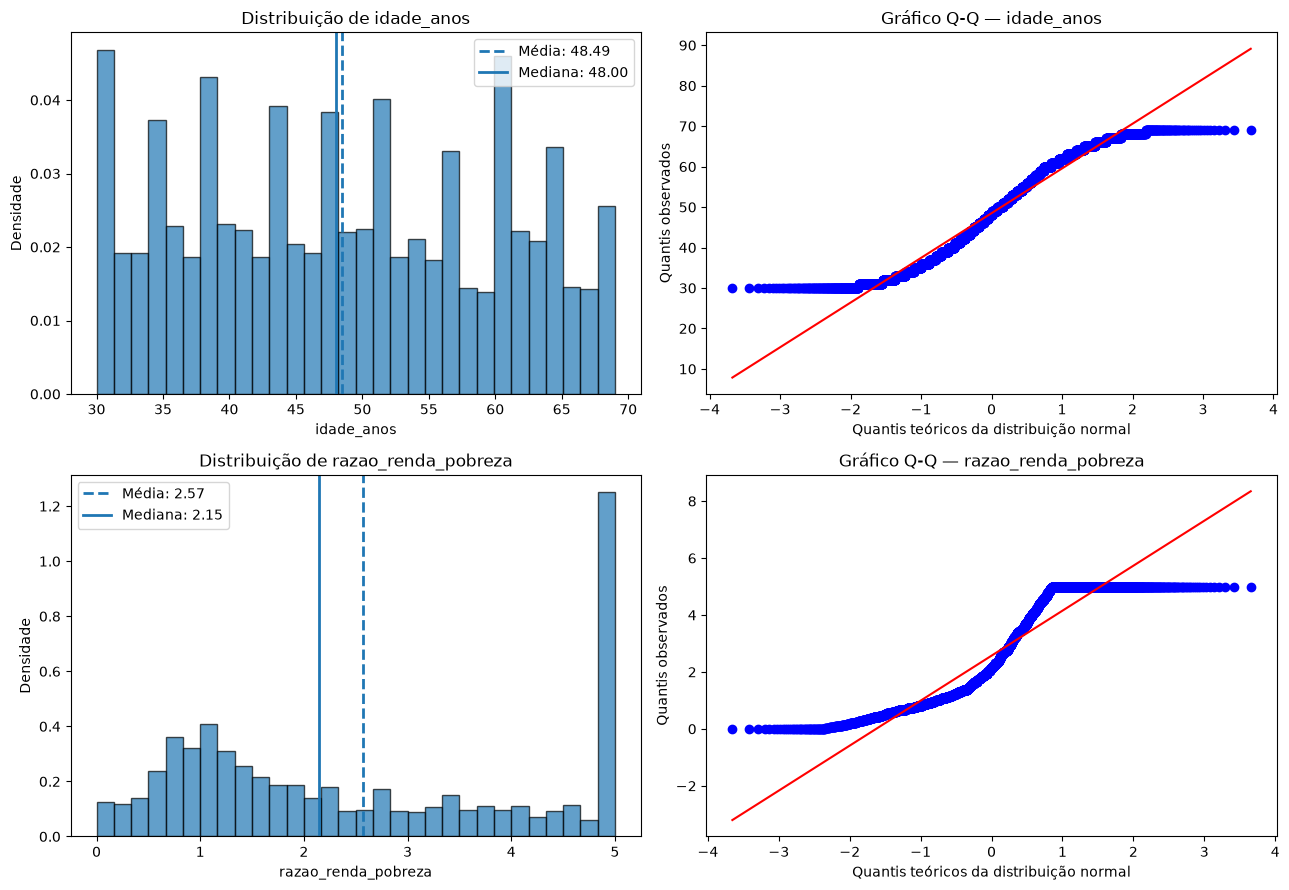

In [20]:
# exploração das estatísticas descritivas das covariáveis numéricas
covariaveis_numericas = [
    "idade_anos",
    "razao_renda_pobreza"
]

resumo_numericas = (
    df_model[covariaveis_numericas]
    .describe()
    .T
)

resumo_numericas["N ausentes"] = (
    df_model[covariaveis_numericas]
    .isna()
    .sum()
)

resumo_numericas["Ausentes (%)"] = (
    100
    * resumo_numericas["N ausentes"]
    / len(df_model)
)

display(resumo_numericas.round(2))
# Criar uma figura com duas linhas e duas colunas.
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for i, variavel in enumerate(covariaveis_numericas):

    # Remover valores ausentes apenas para a visualização.
    dados = df_model[variavel].dropna()

    # ------------------------------------------
    # 1. Histograma
    # ------------------------------------------
    ax_hist = axes[i, 0]

    ax_hist.hist(
        dados,
        bins=30,
        density=True,
        edgecolor="black",
        alpha=0.7
    )

    # Marcar média e mediana.
    ax_hist.axvline(
        dados.mean(),
        linestyle="--",
        linewidth=2,
        label=f"Média: {dados.mean():.2f}"
    )

    ax_hist.axvline(
        dados.median(),
        linestyle="-",
        linewidth=2,
        label=f"Mediana: {dados.median():.2f}"
    )

    ax_hist.set_title(f"Distribuição de {variavel}")
    ax_hist.set_xlabel(variavel)
    ax_hist.set_ylabel("Densidade")
    ax_hist.legend()

    # ------------------------------------------
    # 2. Gráfico Q-Q
    # ------------------------------------------
    ax_qq = axes[i, 1]

    stats.probplot(
        dados,
        dist="norm",
        plot=ax_qq
    )

    ax_qq.set_title(f"Gráfico Q-Q — {variavel}")
    ax_qq.set_xlabel("Quantis teóricos da distribuição normal")
    ax_qq.set_ylabel("Quantis observados")

plt.tight_layout()
plt.show()

### 4.3 Distribuição das classes periodontais após a integração

Antes da modelagem, é importante verificar quantos participantes pertencem a cada categoria. A distribuição das quatro categorias de gravidade é mantida apenas como caracterização clínica descritiva; a distribuição binária apresenta os grupos efetivamente utilizados no treinamento e na avaliação dos Modelos A e B.


,Número de participantes
periodontite_classe,
Sem periodontite,2984
Leve,379
Moderada,1804
Grave,709


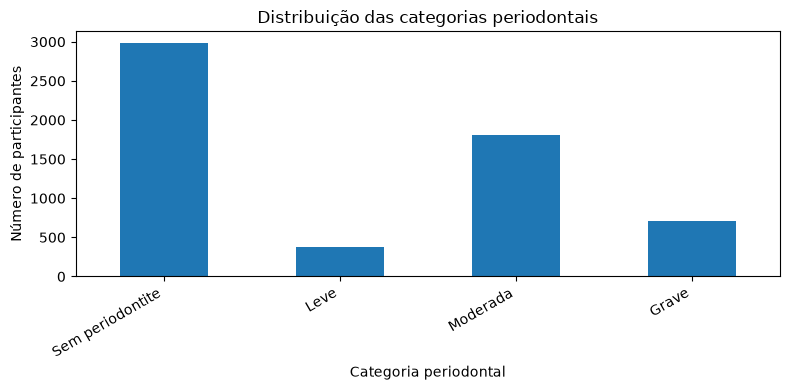

,Número de participantes
periodontite_binaria,
Sem periodontite,2984
Com periodontite,2892


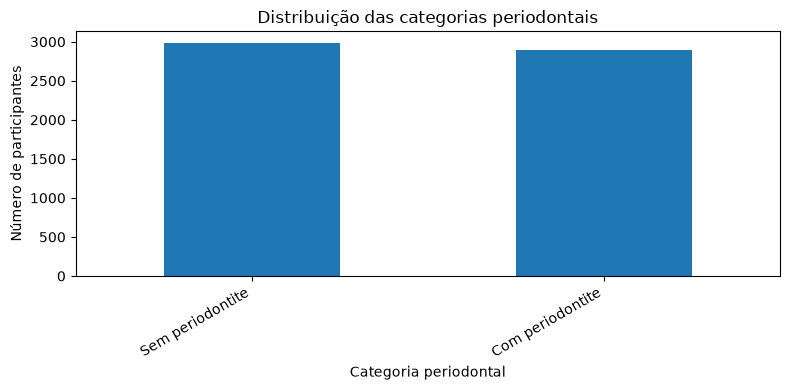

In [21]:
class_order_multi = [
    "Sem periodontite",
    "Leve",
    "Moderada",
    "Grave"
]

class_counts_multi = (
    df_model["periodontite_classe"]
    .value_counts()
    .reindex(class_order_multi, fill_value=0)
)

display(class_counts_multi.rename("Número de participantes").to_frame())

class_counts_multi.plot(kind="bar", figsize=(8, 4))
plt.title("Distribuição das categorias periodontais")
plt.xlabel("Categoria periodontal")
plt.ylabel("Número de participantes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

class_order_bin = [
    "Sem periodontite",
    "Com periodontite"
]

class_counts_bin = (
    df_model["periodontite_binaria"]
    .value_counts()
    .reindex(class_order_bin, fill_value=0)
)

display(class_counts_bin.rename("Número de participantes").to_frame())

class_counts_bin.plot(kind="bar", figsize=(8, 4))
plt.title("Distribuição das categorias periodontais")
plt.xlabel("Categoria periodontal")
plt.ylabel("Número de participantes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


### 4.4 Configuração das covariáveis que serão incluídas no Modelo B


In [22]:
# ============================================================
# Seleção das covariáveis que serão utilizadas no Modelo B
# ============================================================
# True  = incluir a covariável no Modelo B.
# False = excluir a covariável do Modelo B.
# O Modelo A continua utilizando somente os táxons.

CONFIGURACAO_COVARIAVEIS = {
    "idade_anos": True,                  # Idade (anos)
    "sexo": True,                        # Sexo registrado
    "raca_etnia": True,                  # Raça/etnia
    "escolaridade": True,                # Escolaridade
    "estado_civil": True,                # Estado civil
    "razao_renda_pobreza": True,         # Razão renda/pobreza
    "consumo_alcool_categoria": True,    # Categoria de consumo de álcool
    "atividade_fisica_categoria": True,  # Categoria de atividade física
    "hipertensao": True,                 # Hipertensão autorreferida
    "diabetes": True,                    # Diabetes autorreferido
    "doenca_cardiovascular": True,       # Histórico cardiovascular composto
    "historico_cancer": True             # Histórico de câncer
}

# Verificações para evitar erros ao editar a configuração.
if set(CONFIGURACAO_COVARIAVEIS) != set(covariaveis_modelo):
    raise ValueError(
        "As chaves de CONFIGURACAO_COVARIAVEIS devem corresponder "
        "exatamente às covariáveis disponíveis em covariaveis_modelo."
    )

if not all(isinstance(valor, bool) for valor in CONFIGURACAO_COVARIAVEIS.values()):
    raise TypeError("Use somente True ou False na configuração das covariáveis.")

covariaveis_modelo_selecionadas = [
    coluna for coluna in covariaveis_modelo
    if CONFIGURACAO_COVARIAVEIS[coluna]
]

if not covariaveis_modelo_selecionadas:
    raise ValueError(
        "Ative pelo menos uma covariável para executar o Modelo B. "
        "A configuração sem covariáveis corresponde ao Modelo A."
    )

# Separar as covariáveis selecionadas por tipo para o pré-processamento.
COLUNAS_TAXONOMICAS = microbial_cols.copy()
COLUNAS_NUMERICAS_BASE = ["idade_anos", "razao_renda_pobreza"]
COLUNAS_NUMERICAS = [
    coluna for coluna in COLUNAS_NUMERICAS_BASE
    if coluna in covariaveis_modelo_selecionadas
]
COLUNAS_CATEGORICAS = [
    coluna for coluna in covariaveis_modelo_selecionadas
    if coluna not in COLUNAS_NUMERICAS_BASE
]

rotulos_covariaveis = {
    "idade_anos": "Idade (anos)",
    "sexo": "Sexo",
    "raca_etnia": "Raça/etnia",
    "escolaridade": "Escolaridade",
    "estado_civil": "Estado civil",
    "razao_renda_pobreza": "Razão renda/pobreza",
    "consumo_alcool_categoria": "Consumo de álcool",
    "atividade_fisica_categoria": "Atividade física",
    "hipertensao": "Hipertensão",
    "diabetes": "Diabetes",
    "doenca_cardiovascular": "Doença cardiovascular",
    "historico_cancer": "Histórico de câncer"
}

tabela_configuracao_covariaveis = pd.DataFrame({
    "Covariável": [rotulos_covariaveis[c] for c in covariaveis_modelo],
    "Nome no código": covariaveis_modelo,
    "Incluir no Modelo B": [
        "Sim" if CONFIGURACAO_COVARIAVEIS[c] else "Não"
        for c in covariaveis_modelo
    ]
})

print(
    f"Covariáveis selecionadas para o Modelo B: "
    f"{len(covariaveis_modelo_selecionadas)} de {len(covariaveis_modelo)}"
)
print("Covariáveis numéricas:", COLUNAS_NUMERICAS)
print("Covariáveis categóricas:", COLUNAS_CATEGORICAS)
display(tabela_configuracao_covariaveis)


Covariáveis selecionadas para o Modelo B: 12 de 12
Covariáveis numéricas: ['idade_anos', 'razao_renda_pobreza']
Covariáveis categóricas: ['sexo', 'raca_etnia', 'escolaridade', 'estado_civil', 'consumo_alcool_categoria', 'atividade_fisica_categoria', 'hipertensao', 'diabetes', 'doenca_cardiovascular', 'historico_cancer']


,Covariável,Nome no código,Incluir no Modelo B
0,Idade (anos),idade_anos,Sim
1,Sexo,sexo,Sim
2,Raça/etnia,raca_etnia,Sim
3,Escolaridade,escolaridade,Sim
4,Estado civil,estado_civil,Sim
5,Razão renda/pobreza,razao_renda_pobreza,Sim
6,Consumo de álcool,consumo_alcool_categoria,Sim
7,Atividade física,atividade_fisica_categoria,Sim
8,Hipertensão,hipertensao,Sim
9,Diabetes,diabetes,Sim


## 5. Análises exploratórias do microbioma e da integração com covariáveis


### 5.1 PCA exploratória do microbioma após transformação CLR


Participantes utilizados: 5876
Variáveis microbianas inicialmente disponíveis: 107
Valores zero substituídos: 271890
Pseudovalor utilizado: 2.185e-06
Variáveis após remoção das constantes: 107


Variância explicada pela PC1: 10.37%
Variância explicada pela PC2: 9.63%
Variância acumulada: 19.99%


,Táxon,PC1,PC2,Selecionado por
85,Neisseria,0.635,-0.233,PC1
93,Haemophilus,0.608,-0.072,PC1
103,Fretibacterium,-0.601,-0.340,PC1
13,Bacteroidales (ordem),-0.587,-0.255,PC1
33,Lactobacillus,-0.363,0.646,PC2
3,Bifidobacterium,-0.309,0.534,PC2
54,Peptococcus,-0.173,-0.530,PC2
57,Peptostreptococcus,0.164,-0.523,PC2


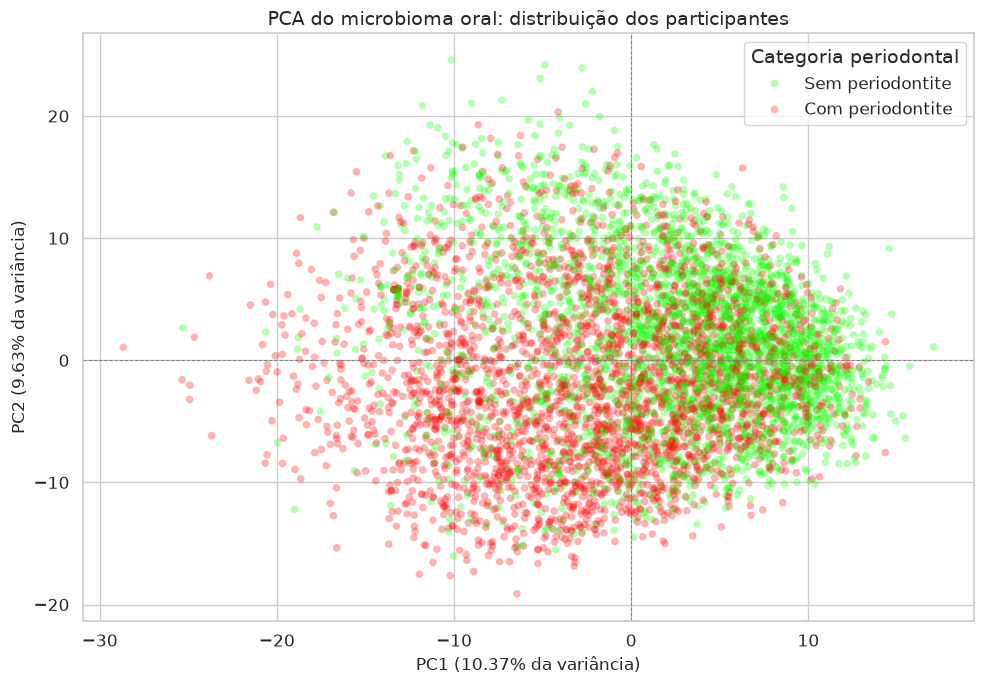

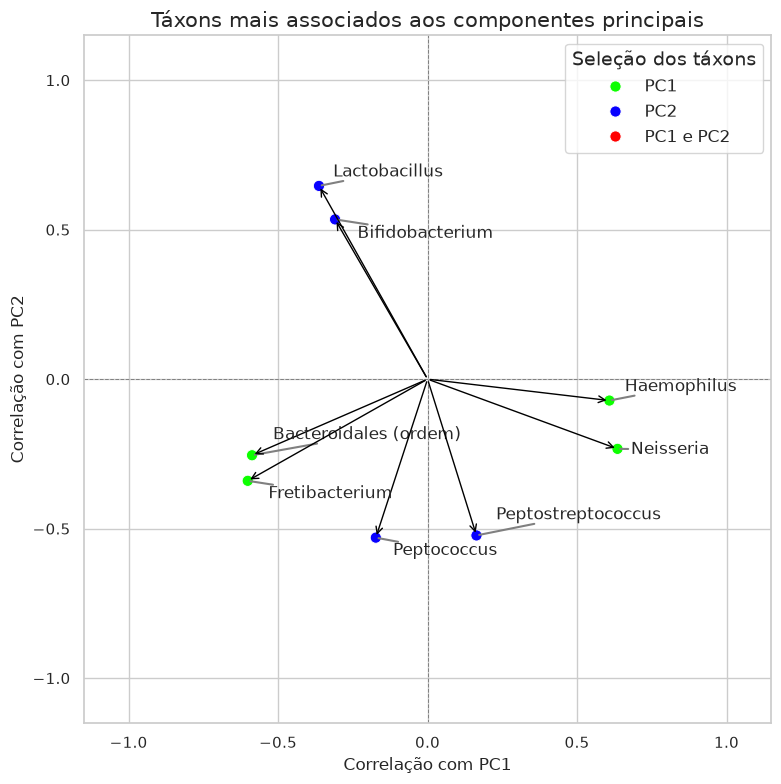


Abundância relativa média dos táxons apresentados como vetores:


,Táxon,PC1,PC2,Selecionado por,Abundância relativa média (%),Ranking de abundância
6,Haemophilus,0.6081,-0.0716,PC1,5.4806,5
5,Neisseria,0.6352,-0.2331,PC1,2.6726,9
2,Lactobacillus,-0.3632,0.6464,PC2,0.5556,17
4,Peptostreptococcus,0.1635,-0.5227,PC2,0.3361,27
0,Bifidobacterium,-0.3094,0.5343,PC2,0.0890,56
3,Peptococcus,-0.1731,-0.5301,PC2,0.0661,64
7,Fretibacterium,-0.6015,-0.3400,PC1,0.0615,67
1,Bacteroidales (ordem),-0.5872,-0.2545,PC1,0.0283,82



15 táxons com maior abundância relativa média:


,Táxon,Abundância relativa média (%),Ranking de abundância
34,Streptococcus,32.2861,1
7,Rothia,11.8711,2
22,Prevotella 7,8.0100,3
70,Veillonella,6.0050,4
93,Haemophilus,5.4806,5
30,Gemella,4.5270,6
71,Fusobacterium,2.7436,7
0,Actinomyces,2.6750,8
85,Neisseria,2.6726,9
19,Prevotella,2.4007,10


Associação de Spearman entre abundância relativa média e maior correlação absoluta com PC1/PC2: rho = 0.082; p = 0.403


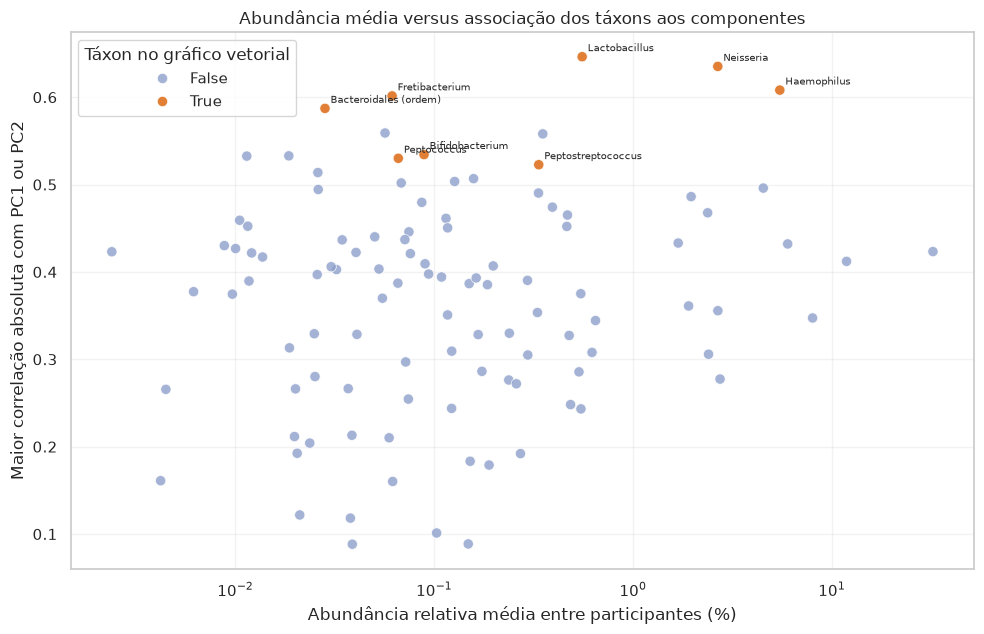

In [23]:
# --------------------------------------------------
# 1. Preparar as categorias periodontais binárias
# --------------------------------------------------

classes_binarias = class_order_bin.copy()

df_pca = df_model.copy()

df_pca["Classe_binaria"] = (
    df_pca["periodontite_binaria"]
    .astype("string")
    .str.strip()
)
df_pca["Classe_multiclasse"] = (
    df_pca["periodontite_classe"]
    .astype("string")
    .str.strip()
)

df_pca = df_pca[
    df_pca["Classe_binaria"].isin(classes_binarias)
    & df_pca["Classe_multiclasse"].isin(class_order_multi)
].copy()

# Extrair as variáveis microbianas
X_df = df_pca[microbial_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

X_original = X_df.to_numpy(dtype=float)

# Remover linhas com valores inválidos ou soma zero
linhas_validas = (
    np.isfinite(X_original).all(axis=1)
    & (X_original >= 0).all(axis=1)
    & (X_original.sum(axis=1) > 0)
)

X_original = X_original[linhas_validas]
df_pca = df_pca.iloc[np.flatnonzero(linhas_validas)].copy()

print("Participantes utilizados:", len(df_pca))
print("Variáveis microbianas inicialmente disponíveis:", X_original.shape[1])

if len(df_pca) < 3:
    raise ValueError("Participantes insuficientes para realizar a PCA.")

if df_pca["Classe_binaria"].nunique() < 2:
    raise ValueError("É necessário haver participantes das duas classes.")

# --------------------------------------------------
# 2. Preparar abundâncias relativas e tratar os zeros
# --------------------------------------------------

# Garantir que as abundâncias de cada participante somem 1
X_rel = X_original / X_original.sum(axis=1, keepdims=True)

# Usar metade da menor abundância positiva como pseudovalor
valores_positivos = X_rel[X_rel > 0]

if len(valores_positivos) == 0:
    raise ValueError("Não foram encontradas abundâncias positivas.")

pseudovalor = valores_positivos.min() / 2
quantidade_zeros = np.count_nonzero(X_rel == 0)

X_rel[X_rel == 0] = pseudovalor

# Reajustar as abundâncias após a substituição dos zeros
X_rel = X_rel / X_rel.sum(axis=1, keepdims=True)

print("Valores zero substituídos:", quantidade_zeros)
print("Pseudovalor utilizado:", f"{pseudovalor:.3e}")

# --------------------------------------------------
# 3. Aplicar a transformação CLR
# --------------------------------------------------

log_rel = np.log(X_rel)

# CLR: log(abundância) menos a média dos logaritmos por participante
X_clr = log_rel - log_rel.mean(axis=1, keepdims=True)

# Remover variáveis microbianas sem variação
desvio_padrao = X_clr.std(axis=0, ddof=1)
colunas_variaveis = desvio_padrao > 1e-12

X_clr = X_clr[:, colunas_variaveis]
generos_clr = np.asarray(microbial_cols)[colunas_variaveis]

print("Variáveis após remoção das constantes:", len(generos_clr))

# --------------------------------------------------
# 4. Calcular os dois primeiros componentes principais
# --------------------------------------------------

pca = PCA(
    n_components=2,
    svd_solver="randomized",
    random_state=42
)

coordenadas = pca.fit_transform(X_clr)

variancia_pc1 = pca.explained_variance_ratio_[0] * 100
variancia_pc2 = pca.explained_variance_ratio_[1] * 100

print(f"Variância explicada pela PC1: {variancia_pc1:.2f}%")
print(f"Variância explicada pela PC2: {variancia_pc2:.2f}%")
print(
    f"Variância acumulada: "
    f"{variancia_pc1 + variancia_pc2:.2f}%"
)

df_scores = pd.DataFrame(
    coordenadas,
    columns=["PC1", "PC2"],
    index=df_pca.index
)

df_scores["Classe_binaria"] = (
    df_pca["Classe_binaria"].to_numpy()
)
df_scores["Classe_multiclasse"] = (
    df_pca["Classe_multiclasse"].to_numpy()
)

# --------------------------------------------------
# 5. Calcular a correlação das variáveis taxonômicas com PC1 e PC2
# --------------------------------------------------

X_centralizado = X_clr - X_clr.mean(axis=0)
scores_centralizados = coordenadas - coordenadas.mean(axis=0)

covariancias = (
    X_centralizado.T @ scores_centralizados
) / (len(X_clr) - 1)

desvio_generos = X_centralizado.std(axis=0, ddof=1)
desvio_scores = scores_centralizados.std(axis=0, ddof=1)

correlacoes = covariancias / (
    desvio_generos[:, None] * desvio_scores[None, :]
)

correlacoes = np.clip(correlacoes, -1, 1)

df_correlacoes = pd.DataFrame({
    "Codigo": generos_clr,
    "PC1": correlacoes[:, 0],
    "PC2": correlacoes[:, 1]
})

# Selecionar os 4 táxons com maior correlação absoluta
# com cada componente. Um táxon pode aparecer nos dois grupos.
n_por_componente = min(4, len(df_correlacoes))

top_pc1 = (
    df_correlacoes
    .assign(Abs_PC1=lambda d: d["PC1"].abs())
    .nlargest(n_por_componente, "Abs_PC1")
)

top_pc2 = (
    df_correlacoes
    .assign(Abs_PC2=lambda d: d["PC2"].abs())
    .nlargest(n_por_componente, "Abs_PC2")
)

codigos_pc1 = set(top_pc1["Codigo"])
codigos_pc2 = set(top_pc2["Codigo"])

# Combinar os resultados sem duplicar táxons
codigos_selecionados = list(
    dict.fromkeys(
        top_pc1["Codigo"].tolist()
        + top_pc2["Codigo"].tolist()
    )
)

df_taxa = df_correlacoes[
    df_correlacoes["Codigo"].isin(codigos_selecionados)
].copy()

df_taxa["Selecionado por"] = df_taxa["Codigo"].apply(
    lambda codigo: (
        "PC1 e PC2"
        if codigo in codigos_pc1 and codigo in codigos_pc2
        else "PC1"
        if codigo in codigos_pc1
        else "PC2"
    )
)

# --------------------------------------------------
# 6. Recuperar nomes pela função de anotação definida na seção 2.2
# --------------------------------------------------

df_taxa["Rótulo"] = rotular_taxons(df_taxa["Codigo"].tolist())

display(
    df_taxa[
        ["Rótulo", "PC1", "PC2", "Selecionado por"]
    ]
    .rename(columns={"Rótulo": "Táxon"})
    .sort_values("PC1", key=lambda s: s.abs(), ascending=False)
    .round(3)
)

# --------------------------------------------------
# 7. Gráfico 1: distribuição dos participantes
# --------------------------------------------------

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(
    data=df_scores,
    x="PC1",
    y="PC2",
    hue="Classe_binaria",
    hue_order=classes_binarias,
    palette={
        "Sem periodontite": "#0dff00",
        "Com periodontite": "#ff0000"
    },
    s=30,
    alpha=0.30,
    linewidth=0,
    ax=ax
)

ax.axhline(0, color="gray", linewidth=0.7, linestyle="--")
ax.axvline(0, color="gray", linewidth=0.7, linestyle="--")

ax.set_xlabel(f"PC1 ({variancia_pc1:.2f}% da variância)", fontsize=12)
ax.set_ylabel(f"PC2 ({variancia_pc2:.2f}% da variância)", fontsize=12)
ax.set_title("PCA do microbioma oral: distribuição dos participantes", fontsize=14)

ax.tick_params(axis="both", labelsize=12)

ax.legend(
    title="Categoria periodontal",
    loc="best",
    fontsize=12,
    title_fontsize=14
)

fig.tight_layout()
plt.show()

# --------------------------------------------------
# 8. Gráfico 2: os mesmos participantes coloridos pelas quatro categorias
# --------------------------------------------------

# fig, ax = plt.subplots(figsize=(10, 7))

# sns.scatterplot(
#     data=df_scores,
#     x="PC1",
#     y="PC2",
#     hue="Classe_multiclasse",
#     hue_order=[c for c in class_order_multi if c in df_scores["Classe_multiclasse"].unique()],
#     s=30,
#     alpha=0.35,
#     linewidth=0,
#     ax=ax
# )

# ax.axhline(0, color="gray", linewidth=0.7, linestyle="--")
# ax.axvline(0, color="gray", linewidth=0.7, linestyle="--")
# ax.set_xlabel(f"PC1 ({variancia_pc1:.2f}% da variância)", fontsize=12)
# ax.set_ylabel(f"PC2 ({variancia_pc2:.2f}% da variância)", fontsize=12)
# ax.set_title("PCA do microbioma oral: quatro categorias periodontais", fontsize=14)
# ax.legend(title="Categoria periodontal", loc="best", fontsize=11)
# fig.tight_layout()
# plt.show()

# --------------------------------------------------
# 9. Gráfico 3: táxons associados aos componentes
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))

sns.scatterplot(
    data=df_taxa,
    x="PC1",
    y="PC2",
    hue="Selecionado por",
    hue_order=["PC1", "PC2", "PC1 e PC2"],
    palette={
        "PC1": "#0dff00",
        "PC2": "#0800ff",
        "PC1 e PC2": "#ff0000"
    },
    s=65,
    ax=ax
)

# Desenhar os vetores e criar os rótulos que serão reposicionados
textos = []

for _, linha in df_taxa.iterrows():
    x = float(linha["PC1"])
    y = float(linha["PC2"])
    rotulo = str(linha["Rótulo"])

    # Desenhar o vetor do táxon a partir da origem
    ax.annotate(
        "",
        xy=(x, y),
        xytext=(0, 0),
        arrowprops={
            "arrowstyle": "->",
            "color": "#000000",
            "linewidth": 1,
            "alpha": 1
        }
    )

    # Criar apenas um rótulo por táxon. Sem adjustText, aplicar deslocamentos
    # fixos em pontos para reduzir sobreposições, inclusive em coordenadas idênticas.
    if adjust_text is not None:
        texto = ax.text(x, y, rotulo, fontsize=12)
        textos.append(texto)
    else:
        deslocamentos = [(8, 8), (8, -10), (-8, 12), (10, 14), (10, -14), (-10, -12)]
        dx, dy = deslocamentos[len(textos) % len(deslocamentos)]
        ax.annotate(
            rotulo,
            xy=(x, y),
            xytext=(dx, dy),
            textcoords="offset points",
            fontsize=12,
            ha="left" if dx >= 0 else "right",
            va="center",
            arrowprops={"arrowstyle": "-", "color": "gray", "linewidth": 0.8, "alpha": 0.8}
        )
        textos.append(rotulo)

ax.axhline(0, color="gray", linewidth=0.7, linestyle="--")
ax.axvline(0, color="gray", linewidth=0.7, linestyle="--")

ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("Correlação com PC1")
ax.set_ylabel("Correlação com PC2")
ax.set_title("Táxons mais associados aos componentes principais", fontsize=15)

ax.legend(
    title="Seleção dos táxons",
    loc="best",
    fontsize=12,
    title_fontsize=14
)

# Reposicionar os rótulos para reduzir sobreposições, quando disponível.
if adjust_text is not None:
    adjust_text(
        textos,
        x=df_taxa["PC1"].to_numpy(),
        y=df_taxa["PC2"].to_numpy(),
        target_x=df_taxa["PC1"].to_numpy(),
        target_y=df_taxa["PC2"].to_numpy(),
        ax=ax,
        force_text=(0.5, 0.8),
        force_static=(0.3, 0.5),
        expand=(1.2, 1.4),
        ensure_inside_axes=True,
        iter_lim=300,
        arrowprops={
            "arrowstyle": "-",
            "color": "gray",
            "linewidth": 1.5,
            "alpha": 1
        }
    )
else:
    print(
        "A biblioteca opcional 'adjustText' não está instalada. "
        "Foram aplicados deslocamentos fixos aos rótulos para reduzir sobreposições. "
        "Para reposicionamento automático, instale com: pip install adjustText."
    )

fig.tight_layout()
plt.show()

# --------------------------------------------------
# 10. Verificar se os táxons vetoriais também estão entre os mais abundantes
# --------------------------------------------------

# Recuperar as abundâncias relativas observadas ANTES da substituição dos zeros.
# Assim, a média inclui zeros reais de não detecção e não incorpora o pseudovalor.
X_rel_observada = X_original / X_original.sum(axis=1, keepdims=True)
media_abundancia_taxons = X_rel_observada.mean(axis=0)

df_abundancia_taxons = pd.DataFrame({
    "Codigo": microbial_cols,
    "Abundância relativa média (%)": media_abundancia_taxons * 100
})
df_abundancia_taxons["Ranking de abundância"] = (
    df_abundancia_taxons["Abundância relativa média (%)"]
    .rank(method="min", ascending=False)
    .astype(int)
)
# Associar a abundância média aos coeficientes dos táxons usados no gráfico vetorial.
df_correlacoes_abundancia = df_correlacoes.merge(
    df_abundancia_taxons,
    on="Codigo",
    how="left",
    validate="one_to_one"
)
df_correlacoes_abundancia["Maior |correlação| com PC1/PC2"] = (
    df_correlacoes_abundancia[["PC1", "PC2"]].abs().max(axis=1)
)
df_correlacoes_abundancia["Ranking de associação com PC1/PC2"] = (
    df_correlacoes_abundancia["Maior |correlação| com PC1/PC2"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Tabela específica dos táxons apresentados como vetores no gráfico.
df_taxa_abundancia = df_taxa.merge(
    df_abundancia_taxons,
    on="Codigo",
    how="left",
    validate="one_to_one"
)
print("\nAbundância relativa média dos táxons apresentados como vetores:")
display(
    df_taxa_abundancia[[
        "Rótulo", "PC1", "PC2", "Selecionado por",
        "Abundância relativa média (%)", "Ranking de abundância"
    ]]
    .rename(columns={"Rótulo": "Táxon"})
    .sort_values("Ranking de abundância")
    .round(4)
)

print("\n15 táxons com maior abundância relativa média:")
df_top_abundantes = df_abundancia_taxons.nlargest(
    15, "Abundância relativa média (%)"
).copy()
df_top_abundantes["Táxon"] = rotular_taxons(df_top_abundantes["Codigo"].tolist())
display(
    df_top_abundantes[[
        "Táxon", "Abundância relativa média (%)", "Ranking de abundância"
    ]].round(4)
)

# Avaliar, de forma exploratória, se abundância média e associação com os PCs
# apresentam uma relação monotônica entre todos os táxons com variância no CLR.
if (
    len(df_correlacoes_abundancia) >= 3
    and df_correlacoes_abundancia["Abundância relativa média (%)"].nunique() > 1
    and df_correlacoes_abundancia["Maior |correlação| com PC1/PC2"].nunique() > 1
):
    rho_abundancia_pca, p_abundancia_pca = stats.spearmanr(
        df_correlacoes_abundancia["Abundância relativa média (%)"],
        df_correlacoes_abundancia["Maior |correlação| com PC1/PC2"]
    )
    print(
        "Associação de Spearman entre abundância relativa média e maior "
        "correlação absoluta com PC1/PC2: "
        f"rho = {rho_abundancia_pca:.3f}; p = {p_abundancia_pca:.3g}"
    )
else:
    rho_abundancia_pca = np.nan
    p_abundancia_pca = np.nan
    print("Não foi possível calcular a associação de Spearman entre abundância e associação aos PCs.")

# Dispersão de todos os táxons; destaque para os táxons exibidos como vetores.
codigos_vetoriais = set(df_taxa["Codigo"])
df_correlacoes_abundancia["Exibido como vetor"] = (
    df_correlacoes_abundancia["Codigo"].isin(codigos_vetoriais)
)

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(
    data=df_correlacoes_abundancia,
    x="Abundância relativa média (%)",
    y="Maior |correlação| com PC1/PC2",
    hue="Exibido como vetor",
    palette={True: "#d95f02", False: "#8da0cb"},
    alpha=0.8,
    s=55,
    ax=ax
)

for _, linha in df_taxa_abundancia.iterrows():
    ax.annotate(
        linha["Rótulo"],
        (
            linha["Abundância relativa média (%)"],
            max(abs(linha["PC1"]), abs(linha["PC2"]))
        ),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7
    )

if (df_correlacoes_abundancia["Abundância relativa média (%)"] > 0).all():
    ax.set_xscale("log")
ax.set_xlabel("Abundância relativa média entre participantes (%)")
ax.set_ylabel("Maior correlação absoluta com PC1 ou PC2")
ax.set_title("Abundância média versus associação dos táxons aos componentes")
ax.grid(alpha=0.25)
ax.legend(title="Táxon no gráfico vetorial")
fig.tight_layout()
plt.show()


### 5.2 PCA integrada: microbioma + covariáveis selecionadas



Participantes na PCA integrada: 5876
Covariáveis selecionadas na configuração 4.4: ['idade_anos', 'sexo', 'raca_etnia', 'escolaridade', 'estado_civil', 'razao_renda_pobreza', 'consumo_alcool_categoria', 'atividade_fisica_categoria', 'hipertensao', 'diabetes', 'doenca_cardiovascular', 'historico_cancer']
Covariáveis efetivamente utilizadas: ['idade_anos', 'sexo', 'raca_etnia', 'escolaridade', 'estado_civil', 'razao_renda_pobreza', 'consumo_alcool_categoria', 'atividade_fisica_categoria', 'hipertensao', 'diabetes', 'doenca_cardiovascular', 'historico_cancer']
Atributos após imputação/codificação: 37
Contribuição do bloco microbioma: 50.0%
Contribuição do bloco covariáveis: 50.0%
Variância explicada pela PC1 integrada: 6.04%
Variância explicada pela PC2 integrada: 5.85%
Variância acumulada integrada: 11.88%


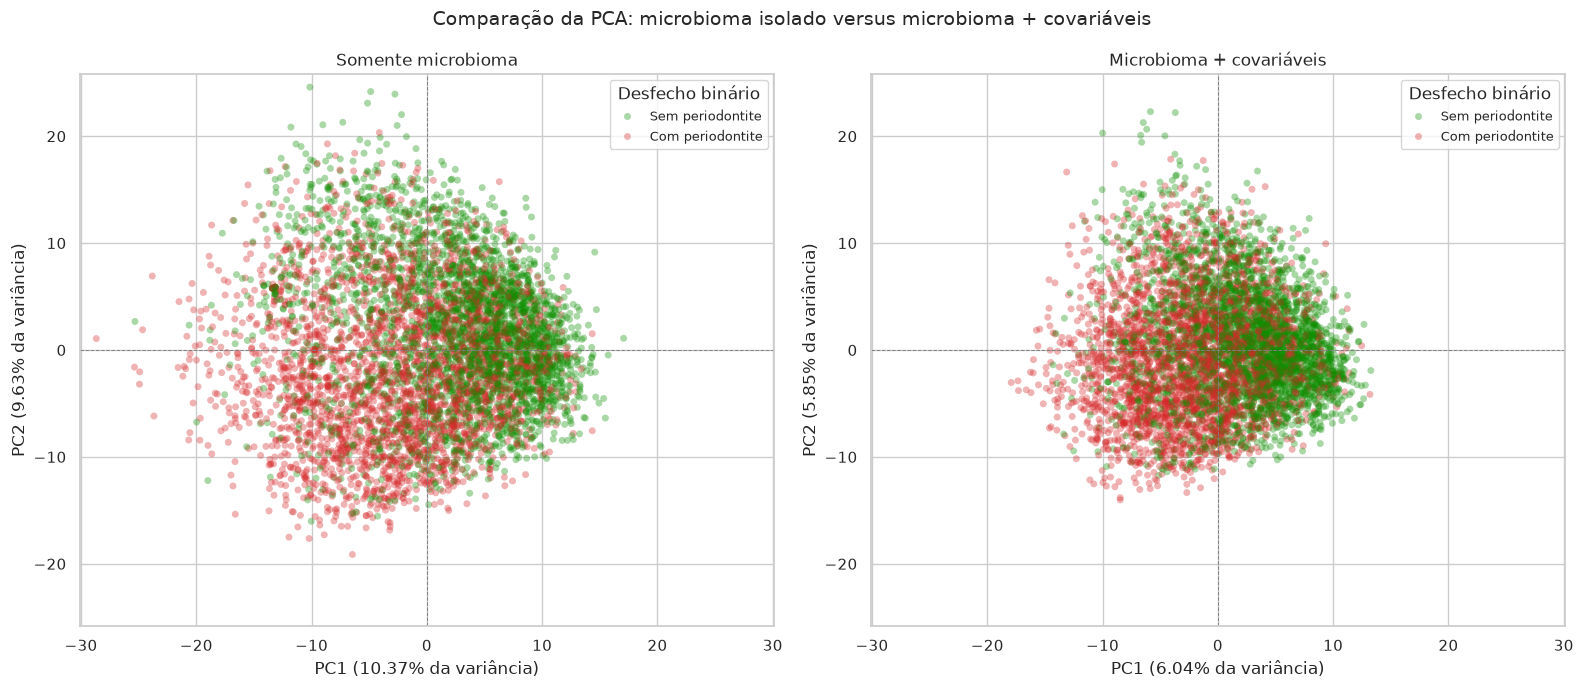

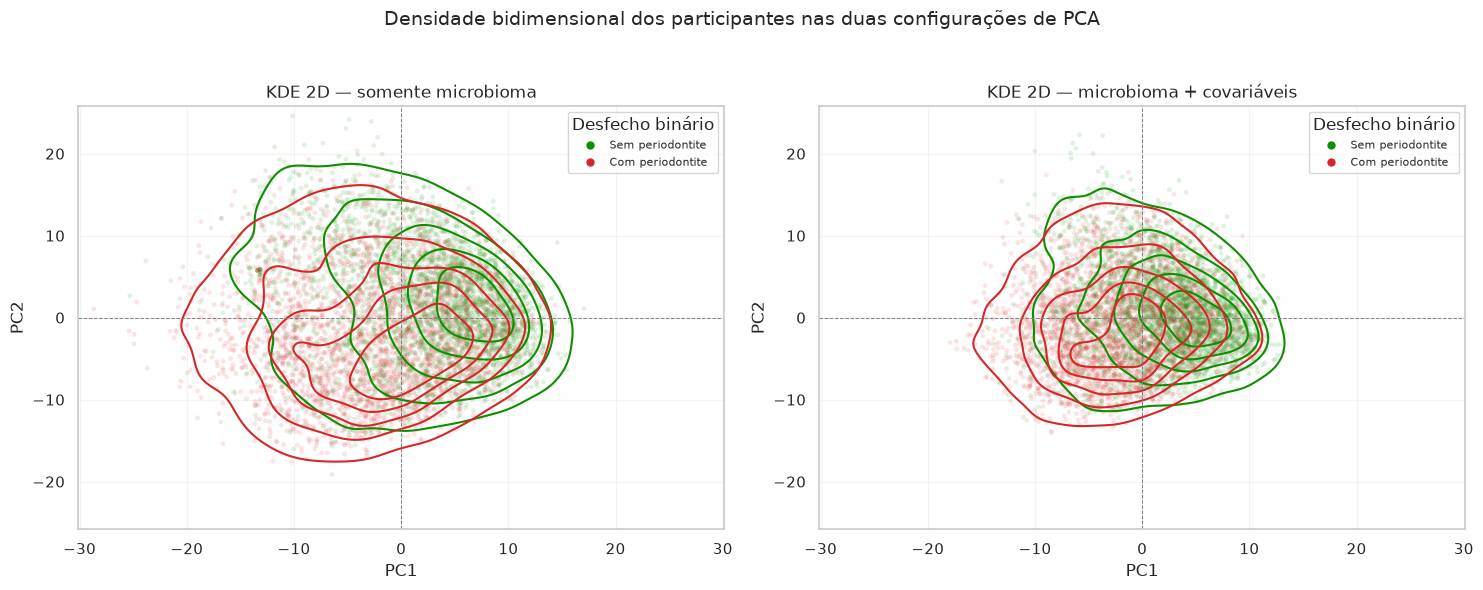


Dispersão de cada categoria no plano dos dois primeiros componentes:


,PCA,Desfecho,Categoria,n,Distância média ao centróide (PC1-PC2),Mediana da distância ao centróide
0,Somente microbioma,Binário,Sem periodontite,2984,8.3498,7.8172
1,Somente microbioma,Binário,Com periodontite,2892,9.0948,8.9497
2,Microbioma + covariáveis,Binário,Sem periodontite,2984,6.4088,6.0257
3,Microbioma + covariáveis,Binário,Com periodontite,2892,6.9498,6.7438



Comparação da dispersão média entre as duas configurações de PCA:


PCA,Desfecho,Categoria,Microbioma + covariáveis,Somente microbioma,Variação relativa da dispersão (%)
0,Binário,Com periodontite,6.950,9.095,-23.585
1,Binário,Sem periodontite,6.409,8.350,-23.246



Atributos de covariáveis mais correlacionados com os componentes da PCA integrada:


,Atributo de covariável,Correlação com PC1,Correlação com PC2,Maior correlação absoluta
0,razao_renda_pobreza,0.461,0.020,0.461
1,hipertensao_Não,0.124,-0.461,0.461
2,hipertensao_Sim,-0.124,0.461,0.461
3,idade_anos,0.022,0.458,0.458
4,escolaridade_Graduação ou superior,0.451,-0.079,0.451
5,doenca_cardiovascular_Sim,-0.146,0.392,0.392
6,doenca_cardiovascular_Não,0.146,-0.392,0.392
7,estado_civil_Casado,0.341,-0.083,0.341
8,diabetes_Não,0.083,-0.327,0.327
9,historico_cancer_Sim,0.060,0.310,0.310


In [24]:
# ============================================================
# PCA integrada: matriz CLR + covariáveis selecionadas
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --------------------------------------------------
# 1. Preparar as covariáveis selecionadas
# --------------------------------------------------

covariaveis_ausentes_df = [
    coluna for coluna in covariaveis_modelo_selecionadas
    if coluna not in df_pca.columns
]
if covariaveis_ausentes_df:
    raise KeyError(
        "Covariáveis selecionadas não encontradas em df_pca: "
        f"{covariaveis_ausentes_df}"
    )

# Manter a mesma amostra utilizada na PCA de referência.
X_covariaveis_pca = df_pca[covariaveis_modelo_selecionadas].copy()

# Variáveis numéricas e categóricas seguem a mesma classificação definida
# na configuração 4.4, mas o pré-processamento abaixo é específico da PCA.
colunas_numericas_pca = [
    coluna for coluna in COLUNAS_NUMERICAS
    if coluna in covariaveis_modelo_selecionadas
]
colunas_categoricas_pca = [
    coluna for coluna in covariaveis_modelo_selecionadas
    if coluna not in colunas_numericas_pca
]

for coluna in colunas_numericas_pca:
    X_covariaveis_pca[coluna] = pd.to_numeric(
        X_covariaveis_pca[coluna], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

for coluna in colunas_categoricas_pca:
    # Converte níveis categóricos para texto e preserva ausências como NaN.
    X_covariaveis_pca[coluna] = X_covariaveis_pca[coluna].map(
        lambda valor: str(valor) if pd.notna(valor) else np.nan
    )

# Covariáveis inteiramente ausentes não podem ser imputadas de forma útil.
covariaveis_sem_observacoes = [
    coluna for coluna in covariaveis_modelo_selecionadas
    if X_covariaveis_pca[coluna].notna().sum() == 0
]
if covariaveis_sem_observacoes:
    print(
        "Covariáveis excluídas da PCA integrada por estarem totalmente ausentes:",
        covariaveis_sem_observacoes
    )

covariaveis_pca_utilizadas = [
    coluna for coluna in covariaveis_modelo_selecionadas
    if coluna not in covariaveis_sem_observacoes
]
if not covariaveis_pca_utilizadas:
    raise ValueError(
        "Nenhuma covariável selecionada possui observações disponíveis para a PCA."
    )

colunas_numericas_pca = [
    coluna for coluna in colunas_numericas_pca
    if coluna in covariaveis_pca_utilizadas
]
colunas_categoricas_pca = [
    coluna for coluna in colunas_categoricas_pca
    if coluna in covariaveis_pca_utilizadas
]

transformadores_covariaveis_pca = []

if colunas_numericas_pca:
    pipeline_numerico_pca = Pipeline(steps=[
        ("imputacao", SimpleImputer(strategy="median")),
        ("padronizacao", StandardScaler())
    ])
    transformadores_covariaveis_pca.append((
        "numericas", pipeline_numerico_pca, colunas_numericas_pca
    ))

if colunas_categoricas_pca:
    # Compatibilidade com versões do scikit-learn que usam 'sparse' em vez
    # de 'sparse_output'.
    try:
        codificador_pca = OneHotEncoder(
            handle_unknown="ignore", sparse_output=False
        )
    except TypeError:
        codificador_pca = OneHotEncoder(
            handle_unknown="ignore", sparse=False
        )

    pipeline_categorico_pca = Pipeline(steps=[
        ("imputacao", SimpleImputer(strategy="most_frequent")),
        ("onehot", codificador_pca),
        ("padronizacao", StandardScaler())
    ])
    transformadores_covariaveis_pca.append((
        "categoricas", pipeline_categorico_pca, colunas_categoricas_pca
    ))

preprocessador_covariaveis_pca = ColumnTransformer(
    transformers=transformadores_covariaveis_pca,
    remainder="drop",
    verbose_feature_names_out=False
)

X_covariaveis_codificadas = preprocessador_covariaveis_pca.fit_transform(
    X_covariaveis_pca[covariaveis_pca_utilizadas]
)
X_covariaveis_codificadas = np.asarray(
    X_covariaveis_codificadas, dtype=float
)
nomes_covariaveis_codificadas = np.asarray(
    preprocessador_covariaveis_pca.get_feature_names_out(), dtype=object
)

# Remover indicadores constantes (por exemplo, níveis categóricos ausentes
# ou covariáveis sem variação na amostra efetivamente analisada).
desvios_covariaveis_pca = X_covariaveis_codificadas.std(axis=0, ddof=1)
colunas_covariaveis_variaveis = desvios_covariaveis_pca > 1e-12
X_covariaveis_codificadas = X_covariaveis_codificadas[
    :, colunas_covariaveis_variaveis
]
nomes_covariaveis_codificadas = nomes_covariaveis_codificadas[
    colunas_covariaveis_variaveis
]

if X_covariaveis_codificadas.shape[1] == 0:
    raise ValueError(
        "As covariáveis selecionadas não produziram atributos variáveis após "
        "imputação e codificação. Verifique a configuração 4.4."
    )

if X_covariaveis_codificadas.shape[0] != X_clr.shape[0]:
    raise ValueError(
        "A matriz de covariáveis e a matriz CLR não possuem o mesmo número de participantes."
    )

print("Participantes na PCA integrada:", len(df_pca))
print("Covariáveis selecionadas na configuração 4.4:", covariaveis_modelo_selecionadas)
print("Covariáveis efetivamente utilizadas:", covariaveis_pca_utilizadas)
print("Atributos após imputação/codificação:", X_covariaveis_codificadas.shape[1])

# --------------------------------------------------
# 2. Igualar a contribuição total dos dois blocos
# --------------------------------------------------

# Centralizar os blocos antes de calcular a contribuição total.
X_clr_centralizado = X_clr - X_clr.mean(axis=0, keepdims=True)
X_covariaveis_centralizadas = (
    X_covariaveis_codificadas
    - X_covariaveis_codificadas.mean(axis=0, keepdims=True)
)

soma_quadrados_microbioma = float(np.square(X_clr_centralizado).sum())
soma_quadrados_covariaveis = float(
    np.square(X_covariaveis_centralizadas).sum()
)

if soma_quadrados_microbioma <= 0 or soma_quadrados_covariaveis <= 0:
    raise ValueError(
        "Não foi possível ponderar os blocos: um deles não apresenta variância."
    )

# Cada bloco passa a responder por metade da variância total da matriz integrada.
peso_microbioma = 1 / np.sqrt(2)
peso_covariaveis = np.sqrt(
    soma_quadrados_microbioma / (2 * soma_quadrados_covariaveis)
)

X_clr_ponderado = X_clr_centralizado * peso_microbioma
X_covariaveis_ponderadas = (
    X_covariaveis_centralizadas * peso_covariaveis
)

X_pca_integrada = np.column_stack([
    X_clr_ponderado,
    X_covariaveis_ponderadas
])

print(
    "Contribuição do bloco microbioma:",
    f"{np.square(X_clr_ponderado).sum() / np.square(X_pca_integrada).sum():.1%}"
)
print(
    "Contribuição do bloco covariáveis:",
    f"{np.square(X_covariaveis_ponderadas).sum() / np.square(X_pca_integrada).sum():.1%}"
)

# --------------------------------------------------
# 3. Ajustar a PCA integrada
# --------------------------------------------------

pca_integrada = PCA(
    n_components=2,
    svd_solver="randomized",
    random_state=42
)
coordenadas_integradas = pca_integrada.fit_transform(X_pca_integrada)

variancia_pc1_integrada = pca_integrada.explained_variance_ratio_[0] * 100
variancia_pc2_integrada = pca_integrada.explained_variance_ratio_[1] * 100
variancia_acumulada_integrada = (
    variancia_pc1_integrada + variancia_pc2_integrada
)

print(f"Variância explicada pela PC1 integrada: {variancia_pc1_integrada:.2f}%")
print(f"Variância explicada pela PC2 integrada: {variancia_pc2_integrada:.2f}%")
print(f"Variância acumulada integrada: {variancia_acumulada_integrada:.2f}%")

# Manter os mesmos participantes e os mesmos rótulos da PCA de referência.
df_scores_integrada = pd.DataFrame(
    coordenadas_integradas,
    columns=["PC1", "PC2"],
    index=df_pca.index
)
df_scores_integrada["Classe_binaria"] = df_pca["Classe_binaria"].to_numpy()
df_scores_integrada["Classe_multiclasse"] = df_pca["Classe_multiclasse"].to_numpy()

# --------------------------------------------------
# 4. Comparar graficamente a PCA de referência e a PCA integrada
#    (somente desfecho binário)
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.set_theme(style="whitegrid")

cores_binarias_pca = {
    "Sem periodontite": "#0d8f00",
    "Com periodontite": "#d62728"
}

configuracoes_graficos_pca = [
    (
        df_scores,
        "Somente microbioma",
        variancia_pc1,
        variancia_pc2
    ),
    (
        df_scores_integrada,
        "Microbioma + covariáveis",
        variancia_pc1_integrada,
        variancia_pc2_integrada
    )
]

for ax, (dados, titulo, var1, var2) in zip(
    axes, configuracoes_graficos_pca
):

    sns.scatterplot(
        data=dados,
        x="PC1",
        y="PC2",
        hue="Classe_binaria",
        hue_order=classes_binarias,
        palette=cores_binarias_pca,
        s=25,
        alpha=0.35,
        linewidth=0,
        ax=ax
    )

    ax.axhline(0, color="gray", linewidth=0.7, linestyle="--")
    ax.axvline(0, color="gray", linewidth=0.7, linestyle="--")

    ax.set_title(titulo, fontsize=12)
    ax.set_xlabel(f"PC1 ({var1:.2f}% da variância)")
    ax.set_ylabel(f"PC2 ({var2:.2f}% da variância)")
    ax.legend(title="Desfecho binário", fontsize=9)

# Utilizar os mesmos limites nos dois painéis
coordenadas_para_limites = np.vstack([
    df_scores[["PC1", "PC2"]].to_numpy(),
    df_scores_integrada[["PC1", "PC2"]].to_numpy()
])

limite_x = np.max(np.abs(coordenadas_para_limites[:, 0])) * 1.05
limite_y = np.max(np.abs(coordenadas_para_limites[:, 1])) * 1.05

for ax in axes:
    ax.set_xlim(-limite_x, limite_x)
    ax.set_ylim(-limite_y, limite_y)

fig.suptitle(
    "Comparação da PCA: microbioma isolado versus microbioma + covariáveis",
    fontsize=14
)

fig.tight_layout()
plt.show()

# --------------------------------------------------
# 4.1 KDE bidimensional: densidade dos participantes por desfecho binário
# --------------------------------------------------

# Os contornos KDE mostram regiões de maior concentração dos participantes.
# A análise é feita para a PCA de referência e para a PCA integrada.
def adicionar_contornos_kde_2d(ax, dados, titulo, paleta, limite_x, limite_y):
    sns.scatterplot(
        data=dados,
        x="PC1",
        y="PC2",
        hue="Classe_binaria",
        hue_order=classes_binarias,
        palette=paleta,
        s=12,
        alpha=0.12,
        linewidth=0,
        legend=False,
        ax=ax
    )

    curvas_adicionadas = 0
    for classe in classes_binarias:
        grupo = dados.loc[dados["Classe_binaria"].eq(classe), ["PC1", "PC2"]].dropna()
        pontos = grupo.to_numpy(dtype=float)

        # KDE bivariada requer número suficiente de observações e variação em
        # duas dimensões; grupos degenerados são ignorados com aviso explícito.
        if len(pontos) < 5 or np.linalg.matrix_rank(np.cov(pontos, rowvar=False)) < 2:
            print(f"KDE não calculada para '{classe}' em '{titulo}': dados insuficientes ou degenerados.")
            continue

        try:
            sns.kdeplot(
                x=grupo["PC1"],
                y=grupo["PC2"],
                levels=6,
                thresh=0.05,
                fill=False,
                color=paleta[classe],
                linewidths=1.5,
                ax=ax
            )
            curvas_adicionadas += 1
        except (ValueError, np.linalg.LinAlgError) as erro:
            print(f"KDE não calculada para '{classe}' em '{titulo}': {erro}")

    ax.axhline(0, color="gray", linewidth=0.7, linestyle="--")
    ax.axvline(0, color="gray", linewidth=0.7, linestyle="--")
    ax.set_xlim(-limite_x, limite_x)
    ax.set_ylim(-limite_y, limite_y)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(titulo)
    ax.grid(alpha=0.2)

    # Legenda manual para não duplicar entradas dos contornos.
    elementos_legenda = [
        Line2D([0], [0], marker="o", color="w", markerfacecolor=paleta[classe],
               markersize=7, label=classe)
        for classe in classes_binarias
    ]
    ax.legend(handles=elementos_legenda, title="Desfecho binário", fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
adicionar_contornos_kde_2d(
    axes[0], df_scores, "KDE 2D — somente microbioma",
    cores_binarias_pca, limite_x, limite_y
)
adicionar_contornos_kde_2d(
    axes[1], df_scores_integrada, "KDE 2D — microbioma + covariáveis",
    cores_binarias_pca, limite_x, limite_y
)
fig.suptitle("Densidade bidimensional dos participantes nas duas configurações de PCA", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# --------------------------------------------------
# 5. Quantificar a dispersão das categorias no plano PC1-PC2
# --------------------------------------------------

registros_dispersao_pca = []

configuracoes_desfechos_dispersao = [
    ("Binário", "Classe_binaria", classes_binarias)
]
configuracoes_modelos_pca = [
    ("Somente microbioma", df_scores),
    ("Microbioma + covariáveis", df_scores_integrada)
]

for nome_pca, dados_scores in configuracoes_modelos_pca:
    for nome_desfecho, coluna_grupo, ordem_grupos in configuracoes_desfechos_dispersao:
        for grupo in ordem_grupos:
            mascara_grupo = dados_scores[coluna_grupo].eq(grupo).to_numpy()
            pontos = dados_scores.loc[mascara_grupo, ["PC1", "PC2"]].to_numpy()
            if len(pontos) == 0:
                continue
            centroide = pontos.mean(axis=0)
            distancias = np.linalg.norm(pontos - centroide, axis=1)
            registros_dispersao_pca.append({
                "PCA": nome_pca,
                "Desfecho": nome_desfecho,
                "Categoria": grupo,
                "n": len(pontos),
                "Distância média ao centróide (PC1-PC2)": float(distancias.mean()),
                "Mediana da distância ao centróide": float(np.median(distancias))
            })

tabela_dispersao_pca_integrada = pd.DataFrame(registros_dispersao_pca)
print("\nDispersão de cada categoria no plano dos dois primeiros componentes:")
display(
    tabela_dispersao_pca_integrada.round(4)
)

# Comparação direta da distância média ao centróide entre as duas PCAs.
tabela_comparacao_dispersao_pca = tabela_dispersao_pca_integrada.pivot_table(
    index=["Desfecho", "Categoria"],
    columns="PCA",
    values="Distância média ao centróide (PC1-PC2)"
).reset_index()

if {
    "Somente microbioma", "Microbioma + covariáveis"
}.issubset(tabela_comparacao_dispersao_pca.columns):
    denominador = tabela_comparacao_dispersao_pca["Somente microbioma"].replace(0, np.nan)
    tabela_comparacao_dispersao_pca["Variação relativa da dispersão (%)"] = (
        (tabela_comparacao_dispersao_pca["Microbioma + covariáveis"] / denominador) - 1
    ) * 100

print("\nComparação da dispersão média entre as duas configurações de PCA:")
display(tabela_comparacao_dispersao_pca.round(3))

# --------------------------------------------------
# 6. Identificar covariáveis codificadas mais correlacionadas com PC1 e PC2
# --------------------------------------------------

X_cov_ponderadas_centralizadas = X_covariaveis_ponderadas - X_covariaveis_ponderadas.mean(axis=0)
scores_integrados_centralizados = (
    coordenadas_integradas - coordenadas_integradas.mean(axis=0)
)

covariancias_cov_pca = (
    X_cov_ponderadas_centralizadas.T @ scores_integrados_centralizados
) / (len(X_cov_ponderadas_centralizadas) - 1)

desvios_cov_pca = X_cov_ponderadas_centralizadas.std(axis=0, ddof=1)
desvios_scores_integrados = scores_integrados_centralizados.std(axis=0, ddof=1)

correlacoes_cov_pca = covariancias_cov_pca / (
    desvios_cov_pca[:, None] * desvios_scores_integrados[None, :]
)
correlacoes_cov_pca = np.clip(correlacoes_cov_pca, -1, 1)

df_correlacoes_cov_pca = pd.DataFrame({
    "Atributo de covariável": nomes_covariaveis_codificadas,
    "Correlação com PC1": correlacoes_cov_pca[:, 0],
    "Correlação com PC2": correlacoes_cov_pca[:, 1]
})
df_correlacoes_cov_pca["Maior correlação absoluta"] = df_correlacoes_cov_pca[
    ["Correlação com PC1", "Correlação com PC2"]
].abs().max(axis=1)

df_correlacoes_cov_pca = df_correlacoes_cov_pca.sort_values(
    "Maior correlação absoluta", ascending=False
).reset_index(drop=True)

print("\nAtributos de covariáveis mais correlacionados com os componentes da PCA integrada:")
display(df_correlacoes_cov_pca.head(15).round(3))


### 5.3 Diversidade alfa (Shannon e riqueza)

Antes dos classificadores, comparamos a diversidade da comunidade microbiana entre os grupos. Usamos **todos os 1.349 gêneros** (sem o filtro de prevalência), já que gêneros raros contam para a riqueza.

Participantes por categoria periodontal (multiclasse):


,n
periodontite_classe,
Sem periodontite,2984
Leve,379
Moderada,1804
Grave,709



Participantes por condição periodontal (binária):


,n
periodontite_binaria,
Sem periodontite,2984
Com periodontite,2892



Resultados dos testes de diversidade alfa:


,Desfecho,Índice,Teste,Estatística,p-valor
0,Multiclasse (4 categorias),Shannon,Kruskal–Wallis,458.334,5.099e-99
1,Binário (com/sem periodontite),Shannon,Mann–Whitney U,3102996.500,1.494e-77
2,Multiclasse (4 categorias),Riqueza_observada,Kruskal–Wallis,587.483,5.210e-127
3,Binário (com/sem periodontite),Riqueza_observada,Mann–Whitney U,2883014.500,1.580e-107


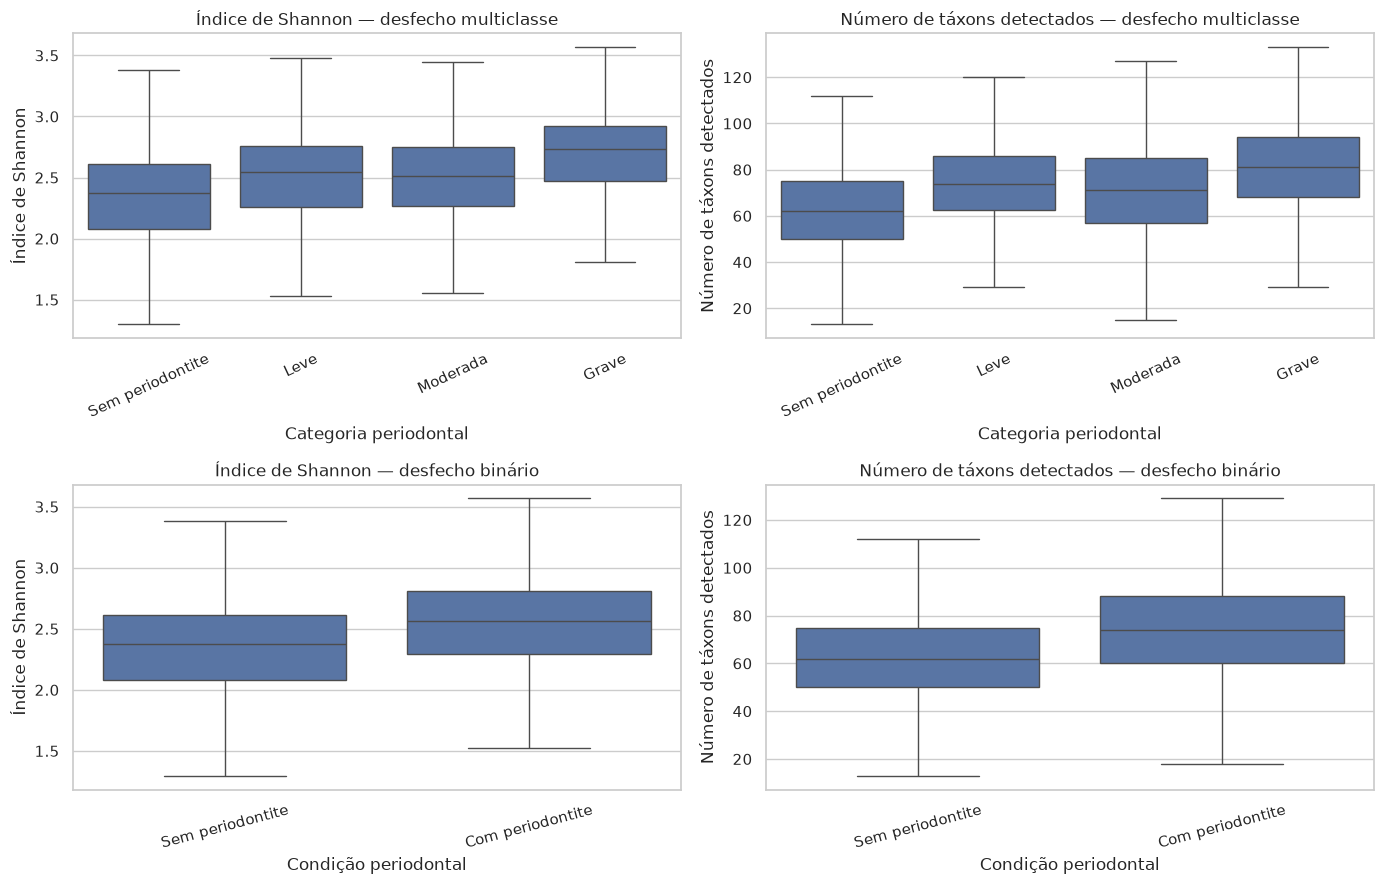

In [25]:
from scipy.stats import kruskal, mannwhitneyu
import seaborn as sns

# A matriz já contém abundâncias relativas por participante.
X_alpha = df_model_sem_filtro[microbial_cols_sem_filtro].to_numpy(dtype=float)
X_alpha = np.clip(X_alpha, 0, None)

# Shannon: H = -sum(p_i * ln(p_i)); os zeros contribuem com zero.
log_p = np.zeros_like(X_alpha, dtype=float)
mascara_positiva = X_alpha > 0
log_p[mascara_positiva] = np.log(X_alpha[mascara_positiva])
shannon = -(X_alpha * log_p).sum(axis=1)

# Riqueza observada: número de táxons detectados em cada amostra.
riqueza_observada = (X_alpha > 0).sum(axis=1)

df_alpha = df_model_sem_filtro[
    ["SEQN", "periodontite_classe", "periodontite_binaria"]
].copy()
df_alpha["Shannon"] = shannon
df_alpha["Riqueza_observada"] = riqueza_observada

ordem_multi_alpha = [
    classe for classe in class_order_multi
    if classe in df_alpha["periodontite_classe"].dropna().unique()
]
ordem_bin_alpha = ["Sem periodontite", "Com periodontite"]

# Tamanho dos grupos em cada forma de classificação.
print("Participantes por categoria periodontal (multiclasse):")
display(
    df_alpha["periodontite_classe"]
    .value_counts()
    .reindex(ordem_multi_alpha)
    .to_frame("n")
)
print("\nParticipantes por condição periodontal (binária):")
display(
    df_alpha["periodontite_binaria"]
    .value_counts()
    .reindex(ordem_bin_alpha)
    .to_frame("n")
)

# Testes globais entre as quatro categorias e entre os dois grupos binários.
resultados_alpha = []
for indice in ["Shannon", "Riqueza_observada"]:
    grupos_multi = [
        df_alpha.loc[
            df_alpha["periodontite_classe"] == classe, indice
        ].dropna().to_numpy()
        for classe in ordem_multi_alpha
    ]
    if len(grupos_multi) >= 2 and all(len(g) > 0 for g in grupos_multi):
        estatistica, p_valor = kruskal(*grupos_multi)
    else:
        estatistica, p_valor = np.nan, np.nan

    grupos_bin = [
        df_alpha.loc[
            df_alpha["periodontite_binaria"] == classe, indice
        ].dropna().to_numpy()
        for classe in ordem_bin_alpha
    ]
    if all(len(g) > 0 for g in grupos_bin):
        estatistica_bin, p_valor_bin = mannwhitneyu(
            grupos_bin[0], grupos_bin[1],
            alternative="two-sided",
            method="asymptotic"
        )
    else:
        estatistica_bin, p_valor_bin = np.nan, np.nan

    resultados_alpha.extend([
        {
            "Desfecho": "Multiclasse (4 categorias)",
            "Índice": indice,
            "Teste": "Kruskal–Wallis",
            "Estatística": estatistica,
            "p-valor": p_valor
        },
        {
            "Desfecho": "Binário (com/sem periodontite)",
            "Índice": indice,
            "Teste": "Mann–Whitney U",
            "Estatística": estatistica_bin,
            "p-valor": p_valor_bin
        }
    ])

tabela_alpha = pd.DataFrame(resultados_alpha)
print("\nResultados dos testes de diversidade alfa:")
display(
    tabela_alpha.style.format({
        "Estatística": "{:.3f}",
        "p-valor": "{:.3e}"
    })
)

# Visualização: primeira linha = quatro categorias; segunda linha = dois grupos.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for coluna, indice in enumerate(["Shannon", "Riqueza_observada"]):
    sns.boxplot(
        data=df_alpha,
        x="periodontite_classe",
        y=indice,
        order=ordem_multi_alpha,
        showfliers=False,
        ax=axes[0, coluna]
    )
    sns.boxplot(
        data=df_alpha,
        x="periodontite_binaria",
        y=indice,
        order=ordem_bin_alpha,
        showfliers=False,
        ax=axes[1, coluna]
    )

    nome_indice = (
        "Índice de Shannon" if indice == "Shannon"
        else "Número de táxons detectados"
    )
    axes[0, coluna].set_title(f"{nome_indice} — desfecho multiclasse")
    axes[1, coluna].set_title(f"{nome_indice} — desfecho binário")
    axes[0, coluna].set_xlabel("Categoria periodontal")
    axes[1, coluna].set_xlabel("Condição periodontal")
    axes[0, coluna].set_ylabel(nome_indice)
    axes[1, coluna].set_ylabel(nome_indice)
    axes[0, coluna].tick_params(axis="x", rotation=25)
    axes[1, coluna].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

**Interpretação e implicações biológicas e computacionais — S1.** Esta análise apresenta duas leituras complementares dos mesmos índices de diversidade. Na visão **multiclasse**, podemos observar se existe um padrão entre as categorias sem periodontite, leve, moderada e grave. Na visão **binária**, avaliamos se a distribuição geral da diversidade difere entre participantes com e sem periodontite. O agrupamento binário simplifica a pergunta e reúne os três níveis de doença em um único grupo.

Shannon aumenta quando há maior diversidade e maior equabilidade entre os táxons; a riqueza observada aumenta quando mais táxons são detectados. Uma diferença entre grupos pode ser compatível com alterações ecológicas da comunidade, mas não demonstra que essas alterações sejam causadas pela periodontite. A direção do padrão deve ser descrita a partir das medianas e distribuições efetivamente observadas, sem pressupor que a diversidade necessariamente diminua ou aumente com a gravidade.

O Kruskal–Wallis testa se pelo menos uma das quatro distribuições difere; o Mann–Whitney U compara as distribuições dos dois grupos binários. Os testes não identificam, por si só, quais pares de categorias diferem. Para essa pergunta seriam necessários testes pós-hoc apropriados. Os p-valores também não quantificam a magnitude da diferença.

Computacionalmente, esta etapa caracteriza a estrutura global dos dados antes da classificação supervisionada. Diferenças de diversidade podem coexistir com grande sobreposição entre indivíduos e com capacidade preditiva limitada. A riqueza observada é sensível à profundidade de sequenciamento e ao limiar de detecção; como não foi aplicada rarefação ou padronização explícita da profundidade nesta etapa, diferenças na riqueza devem ser interpretadas com cautela.

## 6. Protocolo de avaliação e modelo base

### 6.1 Matrizes de entrada

Os modelos recebem as **abundâncias relativas dos 1.349 gêneros** (o filtro de prevalência e a CLR são passos do pipeline, recalculados em cada treino) e, nos Modelos B e C, as covariáveis selecionadas na seção 4.4. Nas covariáveis categóricas, valores ausentes viram a categoria `"ausente"`, uma substituição fixa que não usa nenhuma informação dos outros participantes.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
import xgboost as xgb

from microbioma import FiltroPrevalencia, clr

dados = df_model.set_index("SEQN")
X_taxons = (
    df_model_sem_filtro.set_index("SEQN").loc[dados.index, microbial_cols_sem_filtro]
)
X_cov = dados[covariaveis_modelo_selecionadas].copy()
for coluna in COLUNAS_CATEGORICAS:
    X_cov[coluna] = X_cov[coluna].astype(object).where(X_cov[coluna].notna(), "ausente").astype(str)

X_AB = pd.concat([X_taxons, X_cov], axis=1)
y01 = dados["periodontite_binaria"].map({"Sem periodontite": 0, "Com periodontite": 1})
estratos = dados["periodontite_classe"]  # estratificação pelas 4 categorias

NOMES_TAXONS = dict(zip(microbial_cols_sem_filtro, rotular_taxons(microbial_cols_sem_filtro)))
NOMES_ATRIBUTOS = {**NOMES_TAXONS, **rotulos_covariaveis}

print("Participantes:", len(y01))
print("Gêneros (antes do filtro):", X_taxons.shape[1])
print("Covariáveis:", list(X_cov.columns))
print("Sem / com periodontite:", (y01 == 0).sum(), "/", (y01 == 1).sum())

Participantes: 5876
Gêneros (antes do filtro): 1349
Covariáveis: ['idade_anos', 'sexo', 'raca_etnia', 'escolaridade', 'estado_civil', 'razao_renda_pobreza', 'consumo_alcool_categoria', 'atividade_fisica_categoria', 'hipertensao', 'diabetes', 'doenca_cardiovascular', 'historico_cancer']
Sem / com periodontite: 2984 / 2892


### 6.2 Avaliação repetida com 10 sementes

Uma única divisão treino/teste pode, por acaso, ser mais fácil ou mais difícil que o normal. Por isso **repetimos a divisão com 10 sementes aleatórias** (75% treino, 25% teste, estratificado pelas quatro categorias de gravidade) e reportamos **média ± desvio padrão**. Em cada divisão, tudo o que é aprendido dos dados (filtro, CLR, escolha de hiperparâmetros, treino) usa **apenas o treino**; o teste só é usado para medir o desempenho. Todos os modelos são avaliados nas **mesmas 10 divisões**.

Métricas (aula 03 e v2):

| Métrica | O que mede |
|---|---|
| **AUC (ROC)** | capacidade de ordenar os participantes pelo risco, sem depender de limiar; 0,5 = acaso, 1 = perfeito. Métrica principal. |
| **PR-AUC** | área sob a curva precisão × recall; foca na classe *com periodontite* |
| **Acurácia balanceada** | média entre sensibilidade e especificidade |
| **Sensibilidade** | entre os que têm periodontite, quantos o modelo encontra |
| **Especificidade** | entre os que não têm, quantos o modelo reconhece |
| **F1** | equilíbrio entre precisão e sensibilidade |
| **Brier** | erro quadrático médio das probabilidades (0 = perfeito; quanto menor, mais confiáveis as probabilidades) |

> **Desvios em relação às aulas:** a repetição com várias sementes estende a ideia do `cross_val_score` (aulas 01 e 07); PR-AUC e Brier não aparecem nas aulas e vêm da v2; o `DummyClassifier` serve só como linha de base.

In [27]:
SEMENTES = [42, 1, 2, 3, 4, 5, 6, 7, 8, 9]
SEMENTE_REFERENCIA = 42
TAMANHO_TESTE = 0.25


def avaliar_com_sementes(criar_modelo, X, sementes=SEMENTES):
    # Treina e avalia o modelo em uma divisão treino/teste por semente.
    linhas, referencia, ajustados = [], None, {}
    for semente in sementes:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y01, test_size=TAMANHO_TESTE, random_state=semente, stratify=estratos
        )
        modelo = criar_modelo(semente).fit(X_train, y_train)
        y_pred = modelo.predict(X_test)
        if hasattr(modelo, "predict_proba"):
            y_prob = modelo.predict_proba(X_test)[:, 1]
            brier = brier_score_loss(y_test, y_prob)
        else:  # ex.: SGDClassifier — usa a distância à fronteira para AUC
            y_prob = modelo.decision_function(X_test)
            brier = np.nan
        linhas.append({
            "semente": semente,
            "AUC": roc_auc_score(y_test, y_prob),
            "PR-AUC": average_precision_score(y_test, y_prob),
            "acurácia": accuracy_score(y_test, y_pred),
            "acurácia balanceada": balanced_accuracy_score(y_test, y_pred),
            "sensibilidade": recall_score(y_test, y_pred, pos_label=1),
            "especificidade": recall_score(y_test, y_pred, pos_label=0),
            "F1": f1_score(y_test, y_pred),
            "Brier": brier,
        })
        ajustados[semente] = modelo
        if semente == SEMENTE_REFERENCIA:
            referencia = {"X_test": X_test, "y_test": y_test, "y_pred": y_pred, "y_prob": y_prob}
    return pd.DataFrame(linhas), referencia, ajustados


def resumir(resultados):
    # Tabela média ± desvio por modelo, ordenada pela AUC.
    tabela = pd.concat({nome: r[0] for nome, r in resultados.items()}, names=["modelo"])
    resumo = tabela.drop(columns="semente").groupby("modelo").agg(["mean", "std"])
    return resumo.sort_values(("AUC", "mean"), ascending=False)


def pipeline_taxons(classificador):
    # Modelo A: filtro de prevalência -> CLR -> classificador
    return Pipeline([
        ("filtro", FiltroPrevalencia()),
        ("clr", FunctionTransformer(clr, feature_names_out="one-to-one")),
        ("modelo", classificador),
    ])

### 6.3 Modelo base: CLR + XGBoost (aula de metagenômica)

O primeiro modelo segue a aula *Machine Learning e Metagenômica*: abundâncias → CLR → XGBoost com parâmetros padrão. Ao lado, o `DummyClassifier`, que sempre prevê a classe mais frequente do treino e mostra o desempenho **sem nenhuma informação**.

In [28]:
resultados = {}
resultados["Dummy (classe mais frequente)"] = avaliar_com_sementes(
    lambda s: DummyClassifier(strategy="most_frequent"), X_taxons
)
resultados["A — XGBoost padrão"] = avaliar_com_sementes(
    lambda s: pipeline_taxons(xgb.XGBClassifier(random_state=s, n_jobs=-1)), X_taxons
)
display(resumir(resultados).round(3))

n_generos = [m.named_steps["filtro"].manter_.sum() for m in resultados["A — XGBoost padrão"][2].values()]
print(f"Gêneros mantidos pelo filtro de prevalência em cada treino: {min(n_generos)} a {max(n_generos)}")

AUC       PR-AUC        acurácia        \
                                mean   std   mean    std     mean   std   
modelo                                                                    
A — XGBoost padrão             0.772  0.01  0.772  0.009    0.706  0.01   
Dummy (classe mais frequente)  0.500  0.00  0.492  0.000    0.508  0.00   

                              acurácia balanceada       sensibilidade         \
                                             mean   std          mean    std   
modelo                                                                         
A — XGBoost padrão                          0.706  0.01         0.681  0.015   
Dummy (classe mais frequente)               0.500  0.00         0.000  0.000   

                              especificidade           F1         Brier         
                                        mean   std   mean    std   mean    std  
modelo                                                                          
A — XGBoost padrão                      0.73  0.01  0.695  0.011  0.212  0.006  
Dummy (classe mais frequente)           1.00  0.00  0.000  0.000  0.492  0.000

Gêneros mantidos pelo filtro de prevalência em cada treino: 106 a 112


## 7. Comparação de classificadores (Modelo A)

No mesmo protocolo, comparamos os classificadores trabalhados nas aulas, todos com parâmetros padrão (o ajuste fica para a seção 9):

| Classificador | Aula |
|---|---|
| `LogisticRegression` | 03, 05 e 07 |
| `KNeighborsClassifier` | 03 e 07 |
| `SGDClassifier` | 03 e 07 |
| `DecisionTreeClassifier` | 07 e 12 |
| `RandomForestClassifier` | 16 |
| `XGBClassifier` | metagenômica (seção 6.3) |

LogReg, kNN e SGD dependem da escala dos atributos e recebem um `StandardScaler` dentro do pipeline (aulas 03 e 05), ajustado só no treino.

Avaliando A — Regressão logística ...


Avaliando A — kNN ...


Avaliando A — SGD ...


Avaliando A — Árvore de decisão ...


Avaliando A — Random Forest ...


AUC        PR-AUC        acurácia         \
                                mean    std   mean    std     mean    std   
modelo                                                                      
A — Regressão logística        0.777  0.009  0.776  0.009    0.713  0.007   
A — XGBoost padrão             0.772  0.010  0.772  0.009    0.706  0.010   
A — Random Forest              0.770  0.012  0.757  0.013    0.711  0.011   
A — SGD                        0.729  0.024  0.722  0.031    0.674  0.019   
A — kNN                        0.700  0.017  0.668  0.017    0.656  0.013   
A — Árvore de decisão          0.610  0.014  0.560  0.010    0.609  0.013   
Dummy (classe mais frequente)  0.500  0.000  0.492  0.000    0.508  0.000   

                              acurácia balanceada        sensibilidade         \
                                             mean    std          mean    std   
modelo                                                                          
A — Regressão logística                     0.713  0.007         0.673  0.012   
A — XGBoost padrão                          0.706  0.010         0.681  0.015   
A — Random Forest                           0.710  0.011         0.676  0.018   
A — SGD                                     0.674  0.019         0.660  0.037   
A — kNN                                     0.655  0.013         0.559  0.025   
A — Árvore de decisão                       0.609  0.013         0.597  0.029   
Dummy (classe mais frequente)               0.500  0.000         0.000  0.000   

                              especificidade            F1         Brier  \
                                        mean    std   mean    std   mean   
modelo                                                                     
A — Regressão logística                0.752  0.008  0.698  0.008  0.192   
A — XGBoost padrão                     0.730  0.010  0.695  0.011  0.212   
A — Random Forest                      0.744  0.012  0.697  0.013  0.196   
A — SGD                                0.688  0.049  0.666  0.020    NaN   
A — kNN                                0.750  0.012  0.615  0.019  0.237   
A — Árvore de decisão                  0.621  0.017  0.600  0.019  0.390   
Dummy (classe mais frequente)          1.000  0.000  0.000  0.000  0.492   

                                      
                                 std  
modelo                                
A — Regressão logística        0.004  
A — XGBoost padrão             0.006  
A — Random Forest              0.004  
A — SGD                          NaN  
A — kNN                        0.009  
A — Árvore de decisão          0.013  
Dummy (classe mais frequente)  0.000

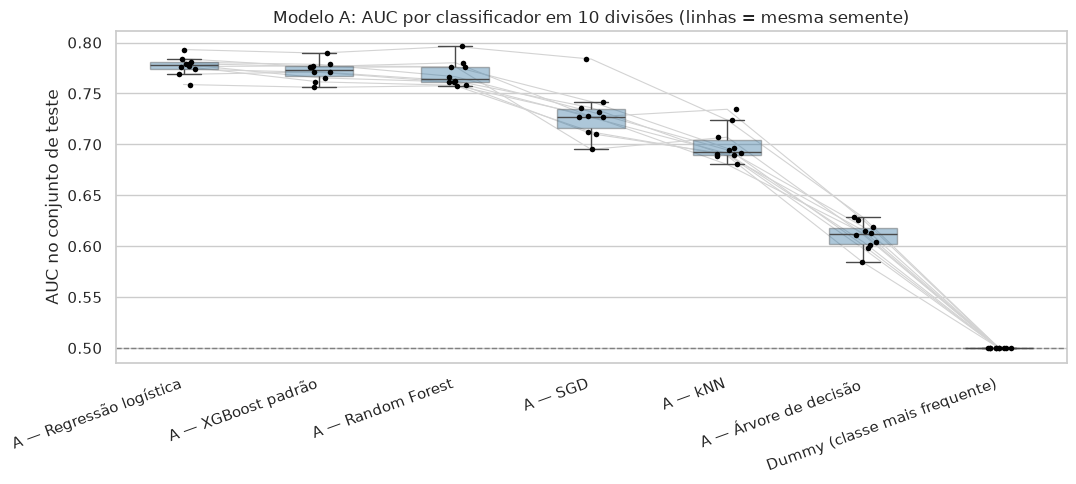

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier


def com_escala(classificador):
    return Pipeline([("escala", StandardScaler()), ("classificador", classificador)])


classificadores = {
    "A — Regressão logística": lambda s: com_escala(LogisticRegression(max_iter=2000, random_state=s)),
    "A — kNN": lambda s: com_escala(KNeighborsClassifier()),
    "A — SGD": lambda s: com_escala(SGDClassifier(random_state=s)),
    "A — Árvore de decisão": lambda s: DecisionTreeClassifier(random_state=s),
    "A — Random Forest": lambda s: RandomForestClassifier(random_state=s, n_jobs=-1),
}
for nome, criar in classificadores.items():
    print(f"Avaliando {nome} ...")
    resultados[nome] = avaliar_com_sementes(lambda s, criar=criar: pipeline_taxons(criar(s)), X_taxons)

display(resumir(resultados).round(3))

auc_por_semente = pd.concat({n: r[0].set_index("semente")["AUC"] for n, r in resultados.items()}, axis=1)
ordem = list(resumir(resultados).index)
fig, ax = plt.subplots(figsize=(11, 5))
for _, linha in auc_por_semente[ordem].iterrows():
    ax.plot(range(len(ordem)), linha.values, color="lightgrey", linewidth=0.8, zorder=1)
sns.boxplot(data=auc_por_semente[ordem], ax=ax, color="tab:blue", width=0.5,
            boxprops={"alpha": 0.4}, showfliers=False, zorder=2)
sns.stripplot(data=auc_por_semente[ordem], ax=ax, color="black", size=4, zorder=3)
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("AUC no conjunto de teste")
ax.set_title("Modelo A: AUC por classificador em 10 divisões (linhas = mesma semente)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 8. Seleção de atributos (aula 04)

### 8.1 Filtro de prevalência e redundância entre gêneros

O filtro de prevalência e abundância (seção 2.1) já é um **método de filtro**: elimina gêneros raros e pouco abundantes antes do treino. A aula 04 também recomenda verificar **atributos muito correlacionados entre si** (|r| ≥ 0,8), que carregam informação repetida. Verificamos isso entre os gêneros mantidos no treino da semente 42:

In [30]:
X_train42, X_test42, y_train42, y_test42 = train_test_split(
    X_taxons, y01, test_size=TAMANHO_TESTE, random_state=SEMENTE_REFERENCIA, stratify=estratos
)
filtro42 = Pipeline([
    ("filtro", FiltroPrevalencia()),
    ("clr", FunctionTransformer(clr, feature_names_out="one-to-one")),
]).fit(X_train42)
clr_train42 = pd.DataFrame(filtro42.transform(X_train42), columns=filtro42.get_feature_names_out(), index=X_train42.index)
clr_test42 = pd.DataFrame(filtro42.transform(X_test42), columns=filtro42.get_feature_names_out(), index=X_test42.index)

correlacoes = clr_train42.corr().abs()
pares = [
    (a, b, correlacoes.loc[a, b])
    for i, a in enumerate(correlacoes.columns)
    for b in correlacoes.columns[i + 1:]
    if correlacoes.loc[a, b] >= 0.8
]
print(f"Gêneros após o filtro (treino da semente 42): {clr_train42.shape[1]}")
print(f"Pares com |correlação| >= 0,8: {len(pares)}")
for a, b, r in sorted(pares, key=lambda t: -t[2])[:10]:
    print(f"  {NOMES_TAXONS[a]} x {NOMES_TAXONS[b]}: {r:.2f}")

Gêneros após o filtro (treino da semente 42): 110
Pares com |correlação| >= 0,8: 1
  Sporichthyaceae (família) x Paracocccus: 0.80


Com o filtro de prevalência, a redundância entre os gêneros que sobram é pequena; por isso não aplicamos uma remoção adicional de correlacionados.

### 8.2 Wrapper: seleção sequencial (SFS)

O método wrapper da aula 04 (`SequentialFeatureSelector` do mlxtend, *forward*) adiciona, a cada passo, o gênero que mais aumenta a AUC na validação cruzada. Partimos dos 50 gêneros mais associados ao desfecho (`SelectKBest(f_classif)`, que ordena os atributos como o módulo da correlação com a resposta usado na aula 04) e permitimos até 10 gêneros.

> **Desvio em relação ao protocolo:** pelo custo computacional, o SFS é feito **só na semente 42**, como análise ilustrativa: **quão bem um conjunto pequeno de gêneros consegue classificar?**

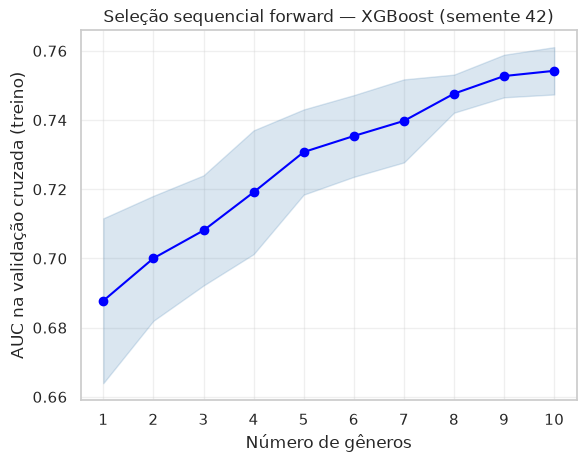

Melhor subconjunto: 10 gêneros
  - Phocaeicola
  - Prevotellaceae (família)
  - Defluviitaleaceae UCG-011
  - Pseudoramibacter
  - Anaeroglobus
  - Leptotrichiaceae (família)
  - Kingella
  - Desulfobulbus
  - Acinetobacter
  - Treponema 2



AUC no teste (semente 42) com os 10 gêneros do SFS: 0.722
AUC no teste (semente 42) com todos os gêneros do filtro: 0.765


In [31]:
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs
from sklearn.feature_selection import SelectKBest, f_classif

top50 = SelectKBest(f_classif, k=50).fit(clr_train42, y_train42).get_feature_names_out()
sfs = SFS(
    xgb.XGBClassifier(random_state=SEMENTE_REFERENCIA, n_jobs=1),
    k_features=(1, 10), forward=True, floating=False, scoring="roc_auc", cv=5, n_jobs=-1,
).fit(clr_train42[top50], y_train42)

plot_sfs(sfs.get_metric_dict(), kind="std_dev")
plt.title("Seleção sequencial forward — XGBoost (semente 42)")
plt.ylabel("AUC na validação cruzada (treino)")
plt.xlabel("Número de gêneros")
plt.grid(alpha=0.3)
plt.show()

generos_sfs = list(sfs.k_feature_names_)
print(f"Melhor subconjunto: {len(generos_sfs)} gêneros")
for codigo in generos_sfs:
    print("  -", NOMES_TAXONS[codigo])

modelo_sfs = xgb.XGBClassifier(random_state=SEMENTE_REFERENCIA, n_jobs=-1).fit(clr_train42[generos_sfs], y_train42)
auc_sfs = roc_auc_score(y_test42, modelo_sfs.predict_proba(clr_test42[generos_sfs])[:, 1])
auc_todos = resultados["A — XGBoost padrão"][0].set_index("semente").loc[SEMENTE_REFERENCIA, "AUC"]
print(f"\nAUC no teste (semente 42) com os {len(generos_sfs)} gêneros do SFS: {auc_sfs:.3f}")
print(f"AUC no teste (semente 42) com todos os gêneros do filtro: {auc_todos:.3f}")

## 9. Ajuste de hiperparâmetros (aula 05)

Seguindo a aula 05, ajustamos o XGBoost com o `RandomizedSearchCV` para os Modelos A e B:

| Hiperparâmetro | O que controla | Valores testados |
|---|---|---|
| `n_estimators` | número de árvores | 100, 200, 400 |
| `max_depth` | profundidade de cada árvore | 2, 3, 4, 6 |
| `learning_rate` | peso de cada nova árvore | entre 0,02 e 0,3 (escala log) |
| `subsample` | fração dos participantes usada em cada árvore | 0,7 ou 1,0 |
| `colsample_bytree` | fração dos atributos sorteada para cada árvore | 0,3, 0,5 ou 0,8 |

**Validação cruzada aninhada:** em cada uma das 10 sementes, a busca (10 combinações sorteadas, validação cruzada de 3 partes, AUC como critério) usa **só o treino**; o melhor pipeline é então avaliado no teste. A média das 10 sementes estima o desempenho do **procedimento completo**, sem otimismo por escolher hiperparâmetros olhando para o teste. Leva alguns minutos.

O **Modelo B** junta os gêneros (filtro + CLR) com as covariáveis: as numéricas entram como estão (o XGBoost lida com valores ausentes) e as categóricas são convertidas em colunas 0/1 (`OneHotEncoder`). O **Modelo C** usa só as covariáveis, com o XGBoost padrão, como referência.

In [32]:
from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV

ESPACO_BUSCA = {
    "modelo__n_estimators": [100, 200, 400],
    "modelo__max_depth": [2, 3, 4, 6],
    "modelo__learning_rate": loguniform(0.02, 0.3),
    "modelo__subsample": [0.7, 1.0],
    "modelo__colsample_bytree": [0.3, 0.5, 0.8],
}


def preprocessador_covariaveis():
    return [
        ("numericas", "passthrough", COLUNAS_NUMERICAS),
        ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), COLUNAS_CATEGORICAS),
    ]


def pipeline_B(classificador):
    # Modelo B: (filtro + CLR nos gêneros) + covariáveis -> classificador
    preparo = ColumnTransformer([
        ("taxons", Pipeline([
            ("filtro", FiltroPrevalencia()),
            ("clr", FunctionTransformer(clr, feature_names_out="one-to-one")),
        ]), microbial_cols_sem_filtro),
        *preprocessador_covariaveis(),
    ])
    return Pipeline([("preparo", preparo), ("modelo", classificador)])


def pipeline_C(classificador):
    # Modelo C: só covariáveis
    return Pipeline([("preparo", ColumnTransformer(preprocessador_covariaveis())), ("modelo", classificador)])


def busca(pipeline, semente):
    # Cada XGBoost usa 1 núcleo e a busca roda várias combinações em paralelo.
    return RandomizedSearchCV(
        pipeline, ESPACO_BUSCA, n_iter=10, cv=3, scoring="roc_auc",
        random_state=semente, n_jobs=-1, refit=True,
    )


print("Modelo A ajustado ...")
resultados["A — XGBoost ajustado"] = avaliar_com_sementes(
    lambda s: busca(pipeline_taxons(xgb.XGBClassifier(random_state=s, n_jobs=1)), s), X_taxons
)
print("Modelo B ajustado ...")
resultados["B — XGBoost ajustado"] = avaliar_com_sementes(
    lambda s: busca(pipeline_B(xgb.XGBClassifier(random_state=s, n_jobs=1)), s), X_AB
)
print("Modelo C (só covariáveis) ...")
resultados["C — XGBoost padrão (só covariáveis)"] = avaliar_com_sementes(
    lambda s: pipeline_C(xgb.XGBClassifier(random_state=s, n_jobs=-1)), X_cov
)

escolhas = pd.DataFrame({
    f"{nome} — semente {s}": {k.removeprefix("modelo__"): v for k, v in m.best_params_.items()}
    for nome in ["A — XGBoost ajustado", "B — XGBoost ajustado"]
    for s, m in resultados[nome][2].items()
}).T
display(escolhas.round(3))

Modelo A ajustado ...


Modelo B ajustado ...


Modelo C (só covariáveis) ...


,colsample_bytree,learning_rate,max_depth,n_estimators,subsample
A — XGBoost ajustado — semente 42,0.3,0.023,4.0,400.0,0.7
A — XGBoost ajustado — semente 1,0.3,0.026,6.0,400.0,1.0
A — XGBoost ajustado — semente 2,0.8,0.033,6.0,400.0,0.7
A — XGBoost ajustado — semente 3,0.3,0.022,6.0,400.0,0.7
A — XGBoost ajustado — semente 4,0.5,0.020,6.0,200.0,0.7
A — XGBoost ajustado — semente 5,0.5,0.075,6.0,400.0,1.0
A — XGBoost ajustado — semente 6,0.3,0.028,3.0,400.0,0.7
A — XGBoost ajustado — semente 7,0.8,0.041,3.0,400.0,0.7
A — XGBoost ajustado — semente 8,0.3,0.063,3.0,200.0,0.7
A — XGBoost ajustado — semente 9,0.3,0.029,4.0,400.0,0.7


## 10. Comparação dos Modelos A, B e C

A tabela reúne todos os modelos, sempre nas mesmas 10 divisões. As comparações principais:

- **A ajustado × A padrão:** quanto o ajuste de hiperparâmetros acrescenta;
- **B × A:** quanto as covariáveis acrescentam ao microbioma;
- **B × C:** quanto o microbioma acrescenta às covariáveis.

AUC        PR-AUC        acurácia  \
                                      mean    std   mean    std     mean   
modelo                                                                     
B — XGBoost ajustado                 0.834  0.010  0.831  0.009    0.750   
A — XGBoost ajustado                 0.789  0.012  0.787  0.013    0.726   
A — Regressão logística              0.777  0.009  0.776  0.009    0.713   
A — XGBoost padrão                   0.772  0.010  0.772  0.009    0.706   
A — Random Forest                    0.770  0.012  0.757  0.013    0.711   
A — SGD                              0.729  0.024  0.722  0.031    0.674   
A — kNN                              0.700  0.017  0.668  0.017    0.656   
C — XGBoost padrão (só covariáveis)  0.697  0.009  0.669  0.011    0.645   
A — Árvore de decisão                0.610  0.014  0.560  0.010    0.609   
Dummy (classe mais frequente)        0.500  0.000  0.492  0.000    0.508   

                                           acurácia balanceada         \
                                       std                mean    std   
modelo                                                                  
B — XGBoost ajustado                 0.015               0.750  0.015   
A — XGBoost ajustado                 0.010               0.726  0.010   
A — Regressão logística              0.007               0.713  0.007   
A — XGBoost padrão                   0.010               0.706  0.010   
A — Random Forest                    0.011               0.710  0.011   
A — SGD                              0.019               0.674  0.019   
A — kNN                              0.013               0.655  0.013   
C — XGBoost padrão (só covariáveis)  0.006               0.645  0.006   
A — Árvore de decisão                0.013               0.609  0.013   
Dummy (classe mais frequente)        0.000               0.500  0.000   

                                    sensibilidade        especificidade  \
                                             mean    std           mean   
modelo                                                                    
B — XGBoost ajustado                        0.722  0.019          0.777   
A — XGBoost ajustado                        0.684  0.013          0.767   
A — Regressão logística                     0.673  0.012          0.752   
A — XGBoost padrão                          0.681  0.015          0.730   
A — Random Forest                           0.676  0.018          0.744   
A — SGD                                     0.660  0.037          0.688   
A — kNN                                     0.559  0.025          0.750   
C — XGBoost padrão (só covariáveis)         0.651  0.011          0.639   
A — Árvore de decisão                       0.597  0.029          0.621   
Dummy (classe mais frequente)               0.000  0.000          1.000   

                                               F1         Brier         
                                       std   mean    std   mean    std  
modelo                                                                  
B — XGBoost ajustado                 0.021  0.740  0.015  0.167  0.005  
A — XGBoost ajustado                 0.014  0.711  0.010  0.188  0.008  
A — Regressão logística              0.008  0.698  0.008  0.192  0.004  
A — XGBoost padrão                   0.010  0.695  0.011  0.212  0.006  
A — Random Forest                    0.012  0.697  0.013  0.196  0.004  
A — SGD                              0.049  0.666  0.020    NaN    NaN  
A — kNN                              0.012  0.615  0.019  0.237  0.009  
C — XGBoost padrão (só covariáveis)  0.015  0.643  0.005  0.237  0.005  
A — Árvore de decisão                0.017  0.600  0.019  0.390  0.013  
Dummy (classe mais frequente)        0.000  0.000  0.000  0.492  0.000

A ajustado − A padrão (ajuste de hiperparâmetros): +0.016 ± 0.005 (positivo em 10 de 10 sementes)
B − A (o que as covariáveis acrescentam): +0.045 ± 0.006 (positivo em 10 de 10 sementes)
B − C (o que o microbioma acrescenta): +0.137 ± 0.010 (positivo em 10 de 10 sementes)


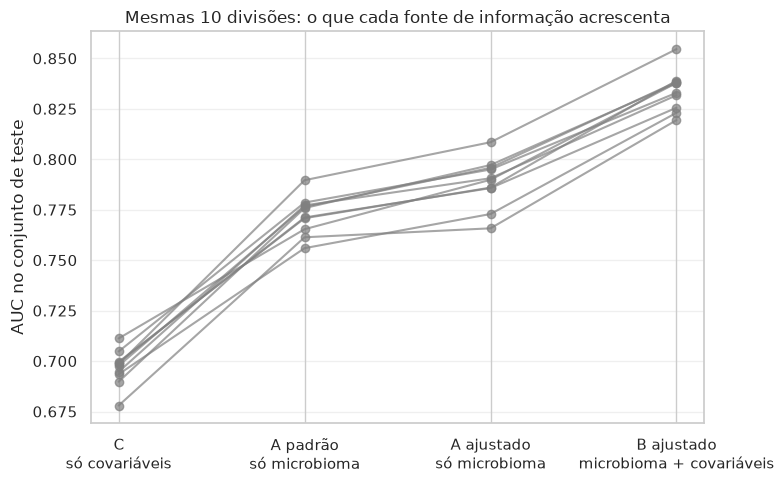

In [33]:
display(resumir(resultados).round(3))

auc = pd.concat({n: r[0].set_index("semente")["AUC"] for n, r in resultados.items()}, axis=1)
comparacoes = {
    "A ajustado − A padrão (ajuste de hiperparâmetros)": auc["A — XGBoost ajustado"] - auc["A — XGBoost padrão"],
    "B − A (o que as covariáveis acrescentam)": auc["B — XGBoost ajustado"] - auc["A — XGBoost ajustado"],
    "B − C (o que o microbioma acrescenta)": auc["B — XGBoost ajustado"] - auc["C — XGBoost padrão (só covariáveis)"],
}
for nome, diferenca in comparacoes.items():
    print(f"{nome}: {diferenca.mean():+.3f} ± {diferenca.std():.3f} "
          f"(positivo em {(diferenca > 0).sum()} de {len(diferenca)} sementes)")

colunas_abc = ["C — XGBoost padrão (só covariáveis)", "A — XGBoost padrão", "A — XGBoost ajustado", "B — XGBoost ajustado"]
fig_abc, ax = plt.subplots(figsize=(8, 5))
for _, linha in auc[colunas_abc].iterrows():
    ax.plot(range(len(colunas_abc)), linha.values, color="grey", marker="o", alpha=0.7)
ax.set_xticks(range(len(colunas_abc)), ["C\nsó covariáveis", "A padrão\nsó microbioma", "A ajustado\nsó microbioma", "B ajustado\nmicrobioma + covariáveis"])
ax.set_ylabel("AUC no conjunto de teste")
ax.set_title("Mesmas 10 divisões: o que cada fonte de informação acrescenta")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

### 10.1 Calibração e desempenho na semente 42

Uma AUC alta diz que o modelo **ordena** bem os participantes, mas não que as **probabilidades** sejam confiáveis. A curva de calibração (v2) compara a probabilidade prevista com a proporção real de periodontite em faixas de probabilidade: um modelo bem calibrado fica perto da diagonal. O escore de Brier da tabela acima resume a mesma ideia.

> **Desvio em relação às aulas:** calibração e Brier não aparecem nas aulas; vêm da v2.

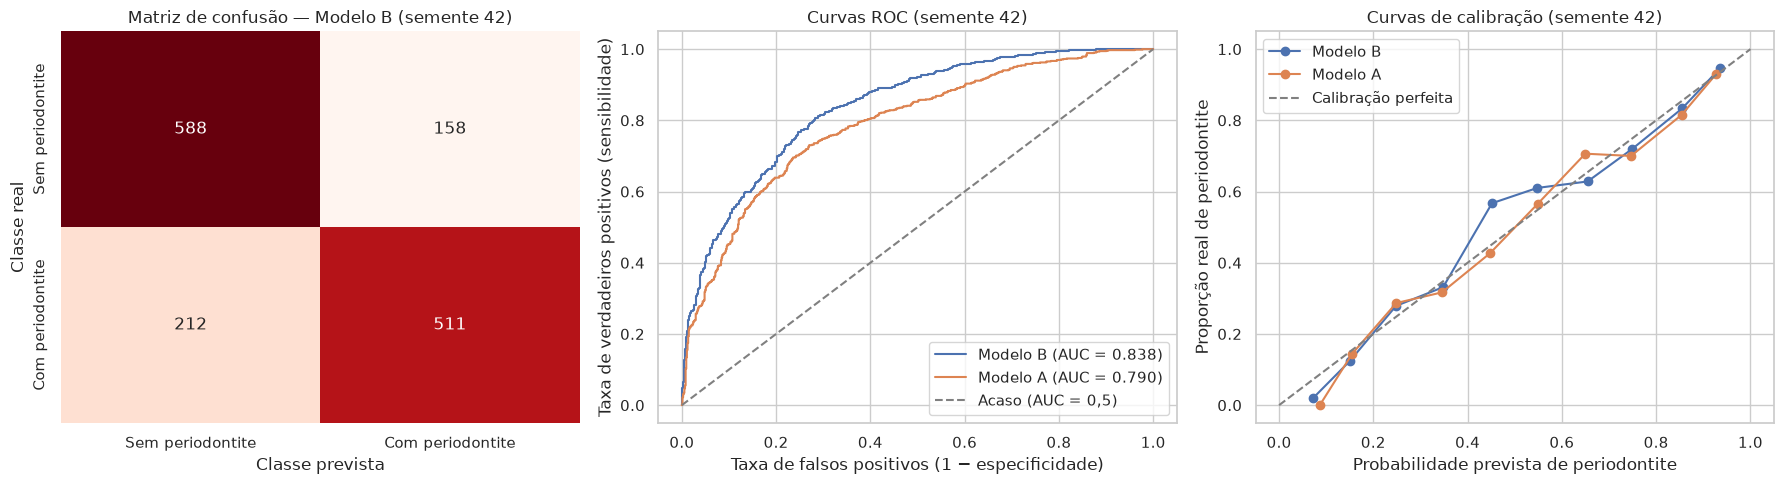

In [34]:
from sklearn.calibration import calibration_curve

nomes_classes = ["Sem periodontite", "Com periodontite"]
ref_B = resultados["B — XGBoost ajustado"][1]
ref_A = resultados["A — XGBoost ajustado"][1]

fig_desempenho, eixos = plt.subplots(1, 3, figsize=(18, 5))
matriz = confusion_matrix(ref_B["y_test"], ref_B["y_pred"])
sns.heatmap(matriz, annot=True, fmt=".0f", cmap="Reds", cbar=False,
            xticklabels=nomes_classes, yticklabels=nomes_classes, ax=eixos[0])
eixos[0].set_title("Matriz de confusão — Modelo B (semente 42)")
eixos[0].set_xlabel("Classe prevista")
eixos[0].set_ylabel("Classe real")

for nome, ref in [("Modelo B", ref_B), ("Modelo A", ref_A)]:
    fpr, tpr, _ = roc_curve(ref["y_test"], ref["y_prob"])
    eixos[1].plot(fpr, tpr, label=f"{nome} (AUC = {roc_auc_score(ref['y_test'], ref['y_prob']):.3f})")
    prob_real, prob_prevista = calibration_curve(ref["y_test"], ref["y_prob"], n_bins=10)
    eixos[2].plot(prob_prevista, prob_real, marker="o", label=nome)
eixos[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Acaso (AUC = 0,5)")
eixos[1].set_xlabel("Taxa de falsos positivos (1 − especificidade)")
eixos[1].set_ylabel("Taxa de verdadeiros positivos (sensibilidade)")
eixos[1].set_title("Curvas ROC (semente 42)")
eixos[1].legend(loc="lower right")
eixos[2].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Calibração perfeita")
eixos[2].set_xlabel("Probabilidade prevista de periodontite")
eixos[2].set_ylabel("Proporção real de periodontite")
eixos[2].set_title("Curvas de calibração (semente 42)")
eixos[2].legend(loc="upper left")
plt.tight_layout()
plt.show()

## 11. Interpretação: o que mais pesa nos modelos

Usamos a **importância por permutação** (v2): embaralhamos os valores de um atributo no conjunto de teste e medimos quanto a AUC cai. Quanto maior a queda, mais o modelo depende daquele atributo. Diferente do `feature_importances_` do XGBoost (aula de metagenômica), ela é calculada no teste e coloca **gêneros e covariáveis na mesma escala**, permitindo compará-los no Modelo B. Usamos os modelos finais da semente 42, com 10 embaralhamentos por atributo.

Importância alta **não indica causa** nem a direção do efeito; indica de quais atributos o modelo mais depende para separar os grupos.

> **Desvio em relação às aulas:** a importância por permutação (`sklearn.inspection.permutation_importance`) não aparece nas aulas; vem da v2.

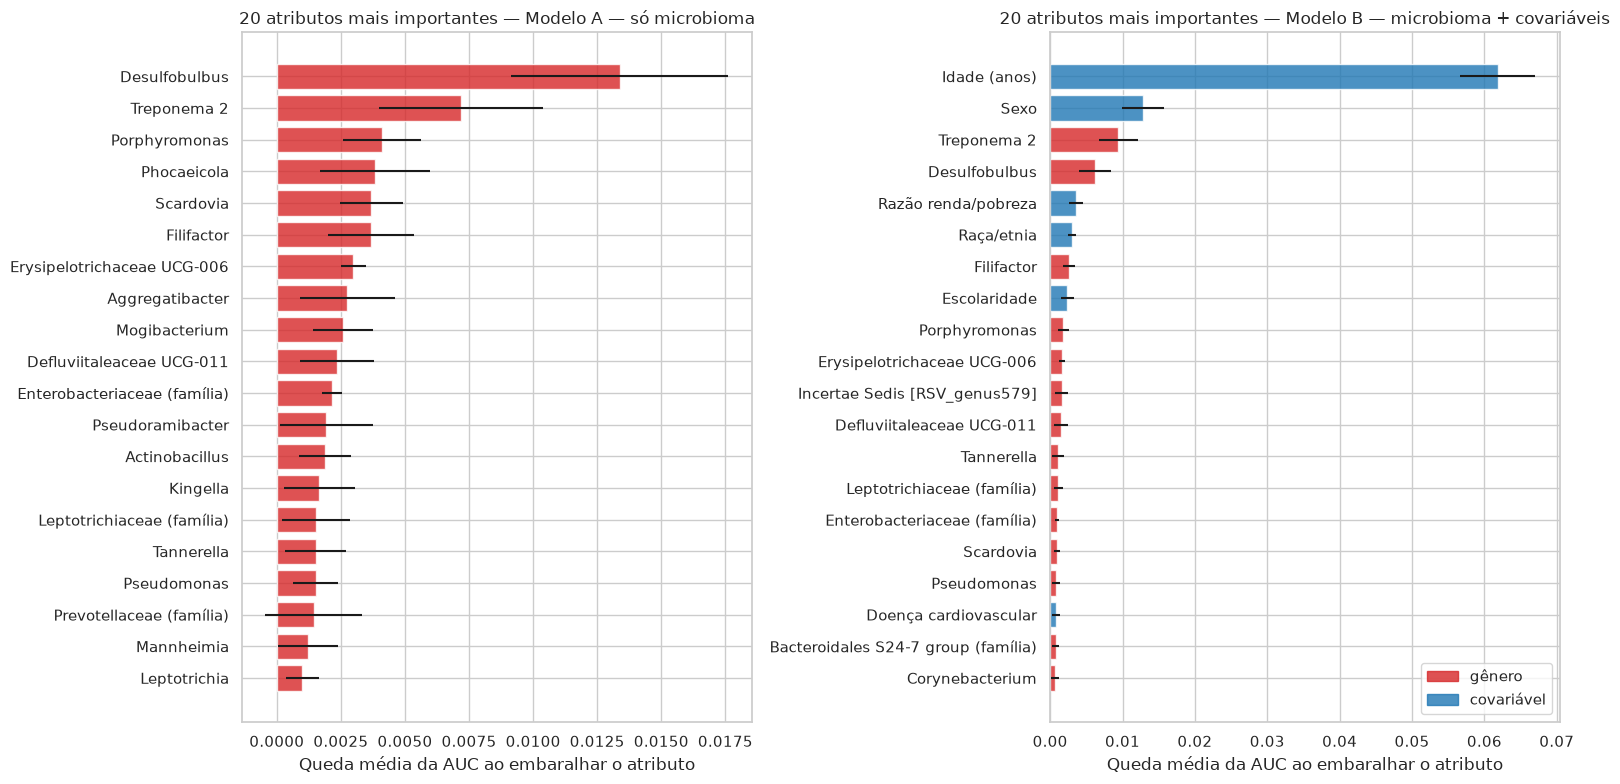

,queda média da AUC,desvio
Idade (anos),0.0618,0.0052
Sexo,0.0128,0.0029
Treponema 2,0.0094,0.0027
Desulfobulbus,0.0062,0.0023
Razão renda/pobreza,0.0035,0.0010
Raça/etnia,0.0030,0.0005
Filifactor,0.0026,0.0008
Escolaridade,0.0024,0.0009
Porphyromonas,0.0018,0.0008
Erysipelotrichaceae UCG-006,0.0017,0.0004


In [35]:
from sklearn.inspection import permutation_importance

modelo_final_A = resultados["A — XGBoost ajustado"][2][SEMENTE_REFERENCIA].best_estimator_
modelo_final_B = resultados["B — XGBoost ajustado"][2][SEMENTE_REFERENCIA].best_estimator_


def importancia_permutacao(modelo, ref):
    r = permutation_importance(modelo, ref["X_test"], ref["y_test"], scoring="roc_auc",
                               n_repeats=10, random_state=SEMENTE_REFERENCIA, n_jobs=-1)
    return pd.DataFrame({"queda média da AUC": r.importances_mean, "desvio": r.importances_std},
                        index=ref["X_test"].columns).sort_values("queda média da AUC", ascending=False)


importancia_A = importancia_permutacao(modelo_final_A, ref_A)
importancia_B = importancia_permutacao(modelo_final_B, ref_B)

fig_importancia, eixos = plt.subplots(1, 2, figsize=(16, 8))
for ax, (titulo, tabela) in zip(eixos, [("Modelo A — só microbioma", importancia_A),
                                         ("Modelo B — microbioma + covariáveis", importancia_B)]):
    top = tabela.head(20).iloc[::-1]
    cores = ["tab:blue" if c in rotulos_covariaveis else "tab:red" for c in top.index]
    ax.barh([NOMES_ATRIBUTOS.get(c, c) for c in top.index], top["queda média da AUC"],
            xerr=top["desvio"], color=cores, alpha=0.8)
    ax.set_xlabel("Queda média da AUC ao embaralhar o atributo")
    ax.set_title(f"20 atributos mais importantes — {titulo}")
eixos[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color="tab:red", alpha=0.8),
                         plt.Rectangle((0, 0), 1, 1, color="tab:blue", alpha=0.8)],
                labels=["gênero", "covariável"], loc="lower right")
plt.tight_layout()
plt.show()

tabela_importancia = importancia_B.head(20).copy()
tabela_importancia.index = [NOMES_ATRIBUTOS.get(c, c) for c in tabela_importancia.index]
display(tabela_importancia.round(4))

## 12. Modelo final e demonstração

O **modelo final** da demonstração é o **Modelo B** ajustado na semente 42; ao lado, a demonstração mostra a probabilidade do **Modelo A** (só microbioma), para comparar quanto vem do microbioma. O desempenho esperado em dados novos é a **média das 10 sementes** (seção 10), não só o resultado da semente 42.

### 12.1 Salvar os resultados para a demonstração

A célula abaixo grava a pasta `resultados/`, lida pelo app (`app.py`): os dois modelos, os participantes do teste da semente 42 (abundâncias e covariáveis), as métricas, os nomes dos gêneros e as figuras. Depois de salvar, ela **recarrega** os arquivos e confere que as probabilidades são idênticas às calculadas aqui.

In [36]:
import shutil
from resultados import carregar_resultados, salvar_resultados

PASTA_RESULTADOS = Path("resultados")
if PASTA_RESULTADOS.exists():
    shutil.rmtree(PASTA_RESULTADOS)

tabela_B = resultados["B — XGBoost ajustado"][0].drop(columns="semente")
tabela_A = resultados["A — XGBoost ajustado"][0].drop(columns="semente")
metricas_demo = {
    "Modelo B — AUC (média em 10 sementes)": round(float(tabela_B["AUC"].mean()), 4),
    "Modelo B — AUC (desvio padrão)": round(float(tabela_B["AUC"].std()), 4),
    "Modelo B — acurácia balanceada (média)": round(float(tabela_B["acurácia balanceada"].mean()), 4),
    "Modelo B — sensibilidade (média)": round(float(tabela_B["sensibilidade"].mean()), 4),
    "Modelo B — especificidade (média)": round(float(tabela_B["especificidade"].mean()), 4),
    "Modelo B — Brier (média)": round(float(tabela_B["Brier"].mean()), 4),
    "Modelo A (só microbioma) — AUC (média)": round(float(tabela_A["AUC"].mean()), 4),
    "Modelo C (só covariáveis) — AUC (média)": round(float(resultados["C — XGBoost padrão (só covariáveis)"][0]["AUC"].mean()), 4),
    "Modelo B — AUC na semente 42 (modelo da demonstração)": round(float(roc_auc_score(ref_B["y_test"], ref_B["y_prob"])), 4),
}

salvar_resultados(
    modelo=modelo_final_B,
    X_teste=ref_B["X_test"],
    y_teste=ref_B["y_test"],
    metricas=metricas_demo,
    figuras={
        "1_desempenho_semente_42": fig_desempenho,
        "2_modelos_A_B_C": fig_abc,
        "3_importancia_por_permutacao": fig_importancia,
    },
    rotulos_atributos=NOMES_TAXONS,
    pasta=PASTA_RESULTADOS,
    modelo_taxons=modelo_final_A,
)

# Conferência: os arquivos salvos reproduzem as probabilidades calculadas aqui
salvo = carregar_resultados(PASTA_RESULTADOS)
X_salvo = salvo.teste.drop(columns="rotulo")
assert np.allclose(salvo.modelo.predict_proba(X_salvo)[:, 1], ref_B["y_prob"])
assert np.allclose(salvo.modelo_taxons.predict_proba(X_salvo[list(salvo.modelo_taxons.feature_names_in_)])[:, 1], ref_A["y_prob"])
print("Resultados salvos e conferidos:")
for arquivo in sorted(PASTA_RESULTADOS.rglob("*")):
    if arquivo.is_file():
        print(f"  {arquivo}  ({arquivo.stat().st_size / 1024:.0f} KB)")

Resultados salvos e conferidos:
  resultados/figuras/1_desempenho_semente_42.png  (201 KB)
  resultados/figuras/2_modelos_A_B_C.png  (133 KB)
  resultados/figuras/3_importancia_por_permutacao.png  (227 KB)
  resultados/metricas.json  (0 KB)
  resultados/modelo.joblib  (733 KB)
  resultados/modelo_taxons.joblib  (685 KB)
  resultados/rotulos_atributos.json  (50 KB)
  resultados/teste.csv.gz  (1082 KB)


### 12.2 Abrir a demonstração (opcional)

A demonstração interativa (`app.py`) mostra o modelo final: escolhe-se um participante do conjunto de teste e vê-se a probabilidade estimada, a condição real e os gêneros mais abundantes, além das métricas e figuras.

Para abrir, troque `ABRIR_DEMO = False` por `ABRIR_DEMO = True` e rode a célula. A demonstração aparece aqui embaixo e, com `share=True`, o Gradio também cria um **link público** (terminado em `.gradio.live`) que funciona por 72 horas, enquanto a sessão estiver aberta. Ela fica desligada por padrão para que **Executar tudo** não fique parado nesta célula.

In [37]:
ABRIR_DEMO = False

if ABRIR_DEMO:
    from app import criar_app_ou_aviso

    criar_app_ou_aviso().launch(share=True)